# GFTM Galerkin field solve: does it make the low-NBASIS max-$\gamma$ width selection reliable on the GS2-KBM cases of R3, M1 and R4?

Fusion_PhD-qp5.24. GFTM's EM field response uses the pointwise quasi-inverses $\mathrm{Mat}(J/p_0)$, $\mathrm{Mat}(J/b_0)$
(`FIELD_GALERKIN F`, production behaviour). The patch `tools/gftm_galerkin_field/gftm_galerkin_field.patch` replaces them
with the Galerkin $\mathrm{Mat}(p_0)^{-1}\mathrm{Mat}(J)$, $\mathrm{Mat}(b_0)^{-1}\mathrm{Mat}(J)$ (`FIELD_GALERKIN T`). On the
laptop (R3, one width, `Fusion_PhD-qp5.23`) this made $D\cdot B$ Hermitian and cut the NBASIS-8 self-convergence error at
ky 0.1, but not at ky 0.3/0.6, where the dominant mode changed identity with NBASIS.

**Data.** Both arms ran on the Galerkin build (md5 `979f191a…`; `=F` is bit-identical to production).
Leaves `GFTM/Runs/LATIN_HYPERCUBE/<case>/kbm_free/gal{F,T}_w<W>_nb<N>_nx<X>/`, registry family `gftm_galerkin_field`:
NBASIS 2/4/8/16 at NXGRID 32 and NBASIS 64 at NXGRID 65, each at the 24 widths 0.2-4.0, FILTER 0.5, IBRANCH $-1$, NMODES 4,
USE_BPAR from the deck. The population is the GS2-KBM samples of each `kbm_free` GS2 cube (user classifier,
docs/mode_filtering.md; $T$ from the cube's saved `tearing_parameter`; converged = $\gamma > 0$ and
`growth_rate_tolerance` < 0.05), selected by Fusion_PhD `results/gftm_galerkin_field/population.py`: GFTM was run on those
samples only, so the population is the samples in each GFTM leaf. GS2 reference: the cube's growth rate and frequency
(pyro's default `time_mode="average"`: the mean over the last 20% of the run) and the time-averaged $|\phi|^2$.

**Dominant mode**: IBRANCH $-1$ returns the modes ranked by growth rate, so mode 0 is the dominant one (checked on every
leaf below). A run with no unstable mode counts as $\gamma = 0$; its frequency, extent and parity drop out.

## Imports and settings

In [1]:
from pathlib import Path
import os
import json
import re
import warnings
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import pyrokinetics
from pyrokinetics import PyroHypercube
from pyrokinetics.diagnostics.extent import Extent

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir()
)
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
load_dotenv(ROOT / "local.env", override=True)
print("pyrokinetics", pyrokinetics.__version__)

analysis_name = "gftm_galerkin_field"
gs2_root = Path(os.environ["GK_DATA_ROOT"]).expanduser() / "GS2" / "Runs" / "LATIN_HYPERCUBE"
# GyroRun wrote this scan to the scratch tree; it has no copy under GK_DATA_ROOT
gftm_root = Path(os.environ["GYRO_DATA_OUTPUT"]) / "GFTM" / "Runs" / "LATIN_HYPERCUBE"
cases = ["R3", "M1", "R4"]
arms = {"F": "pointwise", "T": "Galerkin"}
arm_colours = {"F": "C0", "T": "C3"}
nbasis_all = [2, 4, 8, 16, 64]          # NXGRID 32; NBASIS 64 at NXGRID 65 is the converged self-reference
nbasis_low = [2, 4, 8, 16]
overshoot_tolerance = 0.10              # gamma above the reference by more than 10% is an overshoot
extent_change = np.log10(2)             # a dominant-mode extent change by more than x2 counts as a change of identity
fraction = 0.95                         # pyro Extent: theta range holding 95% of |phi|^2
ky_edges = np.array([0.0, 0.1, 0.3, 0.6, 2.0])
ky_labels = ["<0.1", "0.1-0.3", "0.3-0.6", ">0.6"]
fs_title, fs_legend = 16, 12


def log_xticks(ax, ticks):
    lims = ax.get_xlim()
    ax.set_xticks(ticks)
    ax.set_xlim(lims)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.minorticks_off()

pyrokinetics 0.9.2.dev153+g3290c692


## GFTM leaves

One `PyroHypercube` per leaf; pyro's `Extent` gives the 95% extent of $|\phi|^2$ per mode. The settings each leaf ran with
are GyroRun's `code_flags` in its `manifest.json` (audited against `out.gftm.localdump` in Fusion_PhD, README "Settings audit").
**Parity** of the dominant $\phi$: even fraction $E = \sum|\phi(\theta)+\phi(-\theta)|^2 / (\sum|\phi(\theta)+\phi(-\theta)|^2 +
\sum|\phi(\theta)-\phi(-\theta)|^2)$ on GFTM's symmetric output grid, without pyro's $\sqrt{g_{\theta\theta}}$ weight
(`FieldLine.compute_linear_parity` needs a `Pyro` per sample). Every Hermite function has exact parity, so a GFTM mode has
$E = 0$ or 1 whatever the weight, up to that interpolation (printed below).

In [2]:
warnings.filterwarnings("ignore")
gftm = {}       # (case, arm, NBASIS, WIDTH) -> dominant-mode arrays over the population
names = {}
for case in cases:
    for leaf in sorted((gftm_root / case / "kbm_free").glob("gal*_nb*")):
        gftm_scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
        gftm_scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
        Extent(gftm_scan.gk_output, fraction=fraction)
        flags = json.loads((leaf / "manifest.json").read_text())["code_flags"]
        key = (case, "T" if flags["FIELD_GALERKIN"] else "F", int(flags["NBASIS_MAX"]), round(float(flags["WIDTH"]), 4))
        assert leaf.name.startswith(f"gal{key[1]}_") and f"_nb{key[2]}_" in leaf.name and float(flags["FILTER"]) == 0.5
        gftm_output = gftm_scan.gk_output.data.set_index(sample="sample_name")
        names.setdefault(case, gftm_output.sample.values.astype(str))
        gftm_output = gftm_output.sel(sample=names[case])
        growth = gftm_output.growth_rate.pint.dequantify()
        # IBRANCH -1: GFTM ranks the modes by growth rate, so mode 0 is the dominant one
        assert int(flags["IBRANCH"]) == -1 and (growth.fillna(-np.inf).argmax("mode") == 0).all()
        dominant = gftm_output.isel(mode=0)
        gamma = growth.isel(mode=0).clip(min=0).fillna(0).values           # no unstable mode -> 0
        unstable = gamma > 0
        theta = np.asarray(gftm_output.theta.values, dtype=float)
        phi = dominant.eigenfunctions.sel(field="phi").pint.dequantify().transpose("sample", "theta").values
        # the grid is symmetric only to ~0.01 rad, so phi(-theta) is interpolated (as pyro's compute_linear_parity does)
        phi_flipped = np.array([np.interp(-theta, theta, row.real) + 1j * np.interp(-theta, theta, row.imag) for row in phi])
        even = (np.abs(phi + phi_flipped) ** 2).sum(1)
        even_fraction = even / (even + (np.abs(phi - phi_flipped) ** 2).sum(1))
        gftm[key] = dict(gamma=gamma,
                         omega=np.where(unstable, dominant.mode_frequency.pint.dequantify().values, np.nan),
                         extent=np.where(unstable, dominant.extent.sel(field="phi").pint.dequantify().values, np.nan),
                         even=np.where(unstable, even_fraction, np.nan),
                         units=str(gftm_output.growth_rate.data.units))
        if key[2] == 64:
            gftm[key]["phi"], gftm[key]["theta"] = phi, theta
widths = np.array(sorted({key[3] for key in gftm}))
print("leaves:", pd.Series([key[0] for key in gftm]).value_counts().to_dict(), "| widths:", len(widths), widths.min(), "-", widths.max())
print("population:", {case: len(names[case]) for case in cases})
even_all = np.concatenate([value["even"] for value in gftm.values()])
even_all = even_all[np.isfinite(even_all)]
print("dominant-mode even fraction: share within 0.01 of 0 or 1:", np.mean(np.minimum(even_all, 1 - even_all) < 0.01).round(4))


def stack(case, arm, nbasis, quantity):
    # (width, sample) array of one quantity at one (case, arm, NBASIS)
    return np.array([gftm[case, arm, nbasis, width][quantity] for width in widths])

leaves: {'R3': 240, 'M1': 240, 'R4': 240} | widths: 24 0.2 - 4.0
population: {'R3': 187, 'M1': 140, 'R4': 208}
dominant-mode even fraction: share within 0.01 of 0 or 1: 0.9999


## GS2 reference

The `kbm_free` cube of each case, samples paired with GFTM by `sample_name`. The cube holds the time-averaged $|\phi|^2$
(`eigenfunctions_squared`) on the union of the samples' $\theta$ grids (NaN outside a sample's own grid), not complex
$\phi$; the extent is pyro's `Extent` rule applied to each sample's own grid.

In [3]:
gs2 = {}
for case in cases:
    gs2_scan = PyroHypercube(pyroscan_json=gs2_root / case / "kbm_free" / "pyroscan.json", load_base_pyro=True)
    gs2_scan.load_gk_output(netcdf_file=gs2_root / case / "kbm_free" / "pyroscan.nc")
    gs2_output = gs2_scan.gk_output.data.set_index(sample="sample_name").sel(sample=names[case])
    # same convention (vref_nrl / lref_minor_radius); a cube may tag its units with its normalisation's name
    units = {re.sub(r"_pyroscan_base\d+", "", str(gs2_output.growth_rate.data.units))} | \
            {re.sub(r"_pyroscan_base\d+", "", gftm[key]["units"]) for key in gftm if key[0] == case}
    assert len(units) == 1, units
    phi_squared = gs2_output.eigenfunctions_squared.sel(field="phi").isel(kx=0).pint.dequantify()
    phi_squared = [phi_squared.isel(sample=i).dropna("theta") for i in range(len(names[case]))]
    gamma_gs2 = gs2_output.growth_rate.pint.dequantify().values
    assert (gamma_gs2 > 0).all() and (gs2_output.growth_rate_tolerance.pint.dequantify().values < 0.05).all()
    gs2[case] = dict(gamma=gamma_gs2, omega=gs2_output.mode_frequency.pint.dequantify().values,
                     ky=gs2_output.ky.pint.dequantify().values,
                     phi_squared=phi_squared,
                     extent=np.array([float(Extent._compute(power, fraction)[0]) for power in phi_squared]))
    print(case, "| GS2-KBM samples:", len(names[case]), "| median phi extent:", np.median(gs2[case]["extent"]).round(2),
          "| theta box:", round(float(max(power.theta.max() for power in phi_squared)), 1),
          "| ky bins:", np.bincount(np.digitize(gs2[case]["ky"], ky_edges) - 1, minlength=4).tolist())

R3 | GS2-KBM samples: 187 | median phi extent: 2.45 | theta box: 15.7 | ky bins: [61, 64, 34, 28]


M1 | GS2-KBM samples: 140 | median phi extent: 2.58 | theta box: 15.7 | ky bins: [58, 46, 24, 12]


R4 | GS2-KBM samples: 208 | median phi extent: 2.43 | theta box: 15.7 | ky bins: [66, 68, 41, 33]


## $W_{\rm shape}$: the width whose $N$-function basis best represents the GS2 $\phi(\theta)$

GFTM's basis functions in $\theta$ are $h_j(\theta/W)/\sqrt{W}$, $j < N$, with $h_j$ the orthonormal Hermite functions
($h_0 \propto e^{-x^2/2}$; GFTM's nodes are $\theta_i = W x_i$). For each width the captured fraction is
$C_N(W) = \sum_{j<N} |\langle h_j(\cdot/W)/\sqrt{W}, \phi\rangle|^2 / \int|\phi|^2 d\theta$, the share of $\int|\phi|^2$ held
by the best $N$-function approximation; $W_{\rm shape}(N) = \arg\max_W C_N(W)$ on the 24-width grid. The inner products
are integrals on a uniform 20001-point grid over the sample's own $\theta$ range (30+ points per oscillation of $h_{63}$
at $W = 0.2$), not GFTM's quadrature.

**Approximation:** the GS2 cube holds $|\phi|^2$ only, so the projection is of $|\phi|$, which drops $\phi$'s phase along
$\theta$. The check below repeats the selection on GFTM's own NBASIS-64 $\phi$, once complex and once $|\phi|$.

R3 | median W_shape: {2: 0.8, 4: 0.8, 8: 0.6965, 16: 0.6965, 64: 1.0}


M1 | median W_shape: {2: 0.8, 4: 0.8, 8: 0.6965, 16: 0.6965, 64: 1.0}


R4 | median W_shape: {2: 0.8, 4: 0.8, 8: 0.6063, 16: 0.6063, 64: 1.0}


W_shape from |phi| vs complex phi (GFTM NB64, W 1): median |log10 ratio| by NBASIS, and share within one grid step (0.060 dex)


             median  within_step
case nbasis                     
M1   2        0.000        0.729
     4        0.029        0.686
     8        0.038        0.721
     16       0.028        0.714
R3   2        0.000        0.765
     4        0.000        0.722
     8        0.000        0.722
     16       0.000        0.765
R4   2        0.000        0.769
     4        0.046        0.649
     8        0.051        0.649
     16       0.051        0.644


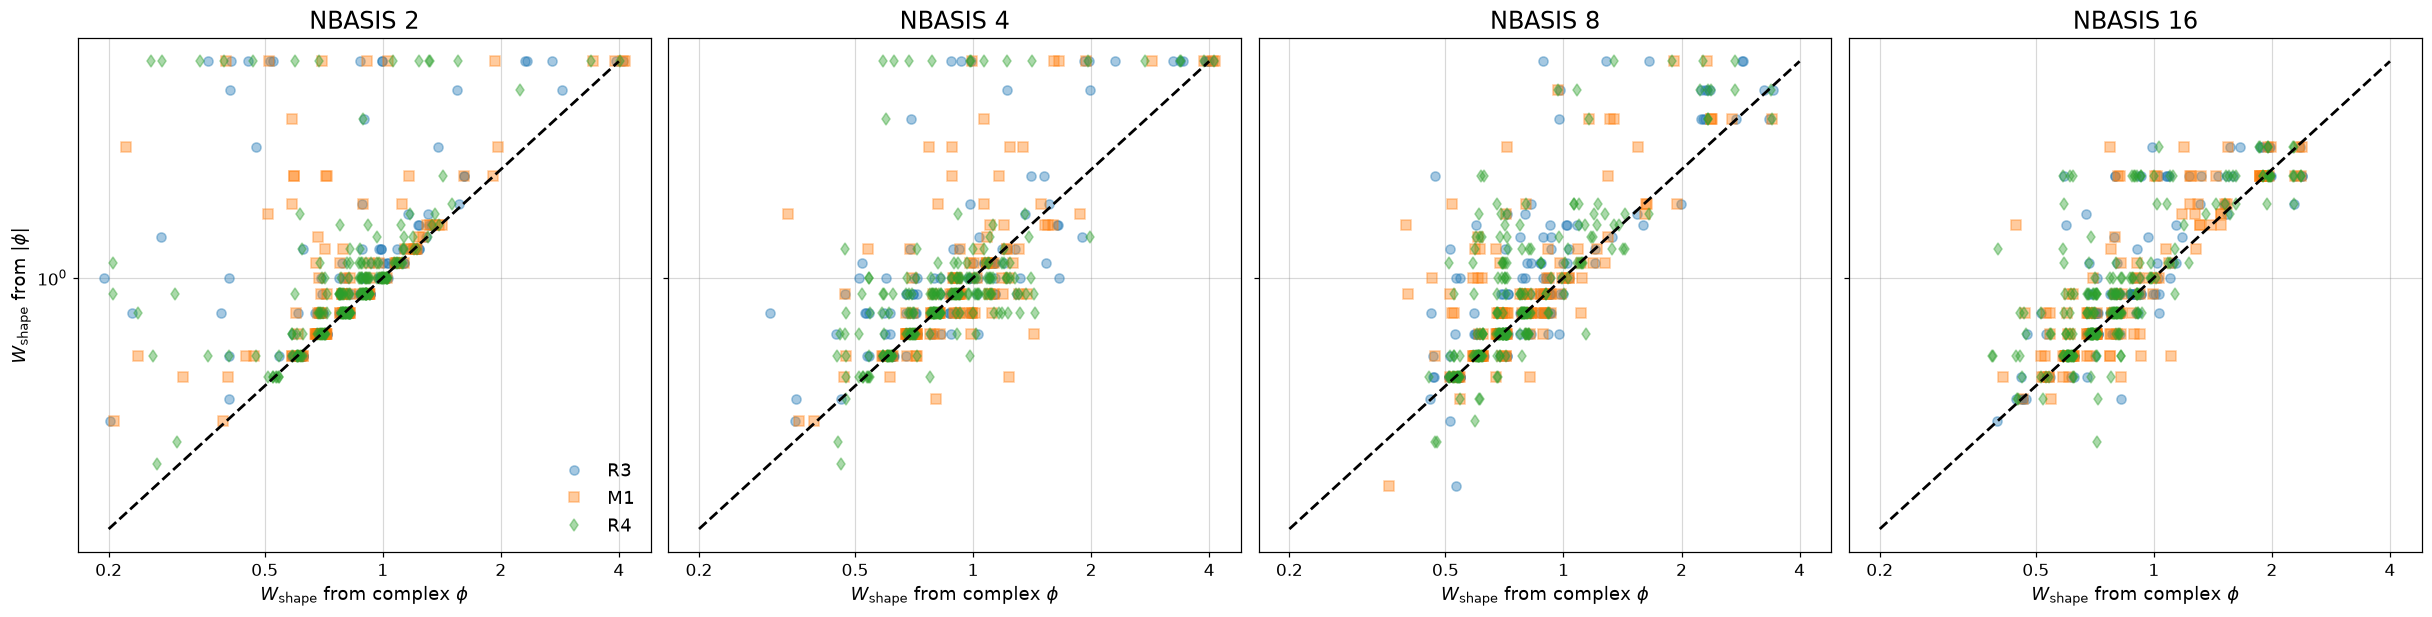

In [4]:
def hermite_functions(n_basis, x):
    # orthonormal Hermite functions h_0 .. h_{n_basis-1} at x, by the stable three-term recursion
    h = np.zeros((n_basis, len(x)))
    h[0] = np.pi ** -0.25 * np.exp(-x ** 2 / 2)
    h[1] = np.sqrt(2) * x * h[0]
    for j in range(2, n_basis):
        h[j] = np.sqrt(2 / j) * x * h[j - 1] - np.sqrt((j - 1) / j) * h[j - 2]
    return h


def captured_fraction(theta, field):
    # C_N(W) for N = 1..64, every grid width: (width, 64) array
    theta_uniform = np.linspace(theta.min(), theta.max(), 20001)
    field_uniform = np.interp(theta_uniform, theta, field.real) + 1j * np.interp(theta_uniform, theta, field.imag)
    norm = np.trapezoid(np.abs(field_uniform) ** 2, theta_uniform)
    captured = []
    for width in widths:
        coefficients = np.trapezoid(hermite_functions(64, theta_uniform / width) * field_uniform, theta_uniform, axis=1) / np.sqrt(width)
        captured.append(np.cumsum(np.abs(coefficients) ** 2) / norm)
    return np.array(captured)


def w_shape(theta, field):
    captured = captured_fraction(theta, field)
    return {nbasis: widths[captured[:, nbasis - 1].argmax()] for nbasis in nbasis_all}


for case in cases:
    shapes = [w_shape(power.theta.values, np.sqrt(power.values) + 0j) for power in gs2[case]["phi_squared"]]
    gs2[case]["w_shape"] = {nbasis: np.array([shape[nbasis] for shape in shapes]) for nbasis in nbasis_all}
    print(case, "| median W_shape:", {nbasis: float(np.median(gs2[case]["w_shape"][nbasis])) for nbasis in nbasis_all})

# check: drop the phase of GFTM's converged phi (Galerkin, NBASIS 64, at the width closest to 1)
width_check = widths[np.abs(widths - 1).argmin()]
phase_check = []
for case in cases:
    entry = gftm[case, "T", 64, width_check]
    for phi, unstable in zip(entry["phi"], entry["gamma"] > 0):
        if unstable:
            complex_shape, magnitude_shape = w_shape(entry["theta"], phi), w_shape(entry["theta"], np.abs(phi) + 0j)
            phase_check += [dict(case=case, nbasis=nbasis, complex=complex_shape[nbasis], magnitude=magnitude_shape[nbasis])
                            for nbasis in nbasis_low]
phase_check = pd.DataFrame(phase_check)
phase_check["dex"] = np.abs(np.log10(phase_check.magnitude / phase_check.complex))
grid_step = np.median(np.diff(np.log10(widths)))
print(f"W_shape from |phi| vs complex phi (GFTM NB64, W {width_check:g}): median |log10 ratio| by NBASIS, and share within one grid step ({grid_step:.3f} dex)")
print(phase_check.groupby(["case", "nbasis"]).dex.agg(median="median", within_step=lambda d: np.mean(d <= grid_step * 1.01)).round(3).to_string())
fig_phase, axes_phase = plt.subplots(1, len(nbasis_low), figsize=(22, 5.5), sharex=True, sharey=True)
for ax, nbasis in zip(axes_phase, nbasis_low):
    for case, marker in zip(cases, "osd"):
        d = phase_check[(phase_check.case == case) & (phase_check.nbasis == nbasis)]
        jitter = 10 ** np.random.default_rng(0).uniform(-0.015, 0.015, len(d))
        ax.plot(d.complex * jitter, d.magnitude, ls="", marker=marker, alpha=0.4, label=case)
    ax.plot(widths[[0, -1]], widths[[0, -1]], color="k", ls="--", marker="")
    ax.set(xscale="log", yscale="log", xlabel=r"$W_{\rm shape}$ from complex $\phi$")
    ax.set_title(f"NBASIS {nbasis}", fontsize=fs_title)
    log_xticks(ax, [0.2, 0.5, 1, 2, 4])
axes_phase[0].set_ylabel(r"$W_{\rm shape}$ from $|\phi|$")
axes_phase[0].legend(fontsize=fs_legend)
plt.show()

## 1. Overshoot rate

Share of (sample, width) pairs at which $\gamma(W, N)$ exceeds the reference by more than 10%. References: (i) the arm's
own converged maximum $\max_W \gamma(W, 64)$, (ii) $\gamma_{\rm GS2}$. Under (i) the max-$\gamma$ selection can only pick a
spurious width if some width overshoots, so (i) at NBASIS 64 is 0 by construction.

In [5]:
rows = []
for case in cases:
    for arm in arms:
        converged_max = stack(case, arm, 64, "gamma").max(0)
        for nbasis in nbasis_all:
            gamma_nb = stack(case, arm, nbasis, "gamma")
            rows.append(dict(case=case, arm=arm, nbasis=nbasis,
                             overshoot_own=np.mean(gamma_nb > (1 + overshoot_tolerance) * converged_max),
                             overshoot_gs2=np.mean(gamma_nb > (1 + overshoot_tolerance) * gs2[case]["gamma"]),
                             any_width_own=np.mean((gamma_nb > (1 + overshoot_tolerance) * converged_max).any(0))))
overshoot = pd.DataFrame(rows)
print(overshoot.round(3).to_string(index=False))

case arm  nbasis  overshoot_own  overshoot_gs2  any_width_own
  R3   F       2          0.222          0.504          0.594
  R3   F       4          0.032          0.333          0.267
  R3   F       8          0.029          0.371          0.225
  R3   F      16          0.021          0.404          0.219
  R3   F      64          0.000          0.351          0.000
  R3   T       2          0.019          0.124          0.123
  R3   T       4          0.024          0.147          0.209
  R3   T       8          0.022          0.168          0.209
  R3   T      16          0.015          0.180          0.193
  R3   T      64          0.000          0.184          0.000
  M1   F       2          0.229          0.471          0.721
  M1   F       4          0.044          0.385          0.350
  M1   F       8          0.049          0.456          0.379
  M1   F      16          0.027          0.473          0.321
  M1   F      64          0.000          0.443          0.000
  M1   T

## 2. Width selection

$W_{\rm sel}(N) = \arg\max_W \gamma(W, N)$ (NaN if no width has an unstable mode). Compared with
$W_\gamma(N)$, the width whose $\gamma(W, N)$ is closest to GS2 (an oracle: it consults the answer), and $W_{\rm shape}(N)$
above; plus $W_{\rm sel}(64)$ of the same arm (does the low-NBASIS search land where the converged search does?). Each is a
median $|\log_{10}|$ ratio over the samples where $W_{\rm sel}$ exists. The grid step is 0.06-0.08 dex.

In [6]:
selection, rows = {}, []
for case in cases:
    samples = np.arange(len(names[case]))
    for arm in arms:
        gamma_64 = stack(case, arm, 64, "gamma")
        for nbasis in nbasis_all:
            gamma_nb = stack(case, arm, nbasis, "gamma")
            pick = gamma_nb.argmax(0)
            found = gamma_nb.max(0) > 0
            selection[case, arm, nbasis] = dict(
                pick=pick, found=found, w_sel=np.where(found, widths[pick], np.nan),
                w_gamma=widths[np.abs(gamma_nb - gs2[case]["gamma"]).argmin(0)])
        for nbasis in nbasis_all:
            sel = selection[case, arm, nbasis]
            rows.append(dict(case=case, arm=arm, nbasis=nbasis, n_found=int(sel["found"].sum()),
                             to_w_gamma=np.nanmedian(np.abs(np.log10(sel["w_sel"] / sel["w_gamma"]))),
                             to_w_shape=np.nanmedian(np.abs(np.log10(sel["w_sel"] / gs2[case]["w_shape"][nbasis]))),
                             to_w_sel64=np.nanmedian(np.abs(np.log10(sel["w_sel"] / selection[case, arm, 64]["w_sel"]))),
                             signed_to_w_gamma=np.nanmedian(np.log10(sel["w_sel"] / sel["w_gamma"])),
                             # a selection on the first or last grid width is the search hitting the range, not a maximum
                             sel_at_edge=np.mean(np.isin(sel["w_sel"], widths[[0, -1]])),
                             w_gamma_at_edge=np.mean(np.isin(sel["w_gamma"], widths[[0, -1]])),
                             same_as_w_gamma=np.mean(sel["w_sel"] == sel["w_gamma"])))
width_selection = pd.DataFrame(rows)
print(width_selection.round(3).to_string(index=False))

case arm  nbasis  n_found  to_w_gamma  to_w_shape  to_w_sel64  signed_to_w_gamma  sel_at_edge  w_gamma_at_edge  same_as_w_gamma
  R3   F       2      187       0.381       0.120       0.699             -0.243        0.043            0.048            0.070
  R3   F       4      187       0.217       0.181       0.456              0.000        0.021            0.064            0.166
  R3   F       8      187       0.318       0.296       0.318              0.125        0.075            0.075            0.144
  R3   F      16      187       0.514       0.409       0.239              0.409        0.150            0.064            0.059
  R3   F      64      187       0.602       0.489       0.000              0.488        0.572            0.150            0.096
  R3   T       2      187       0.000       0.181       0.398              0.000        0.070            0.059            0.668
  R3   T       4      187       0.000       0.181       0.301              0.000        0.070           

## 3. Accuracy at the selected width

Against GS2, over the population (a sample with no unstable mode counts as $\gamma = 0$):
- `logmed_gamma`: $\log_{10}$ median $|\gamma(W_{\rm sel}(N), N) - \gamma_{\rm GS2}|$;
- `two_stage_16`, `two_stage_64`: the same for the re-solve at NBASIS 16 (NXGRID 32) or 64 (NXGRID 65) at $W_{\rm sel}(N)$;
- `oracle`: at $W_\gamma(N)$, a bound, never an accuracy;
- `extent_ratio`: median $|\log_{10}|$ (GFTM $\phi$ extent at $W_{\rm sel}(N)$, NBASIS $N$) / (GS2 $\phi$ extent)| (pyro `Extent`, 95%).

In [7]:
rows = []
for case in cases:
    samples = np.arange(len(names[case]))
    gamma_gs2 = gs2[case]["gamma"]
    logmed = lambda gamma: np.log10(np.median(np.abs(gamma - gamma_gs2)))
    for arm in arms:
        for nbasis in nbasis_all:
            sel = selection[case, arm, nbasis]
            at_sel = lambda nb, quantity="gamma": stack(case, arm, nb, quantity)[sel["pick"], samples]
            at_gamma = stack(case, arm, nbasis, "gamma")[np.searchsorted(widths, sel["w_gamma"]), samples]
            rows.append(dict(case=case, arm=arm, nbasis=nbasis, logmed_gamma=logmed(at_sel(nbasis)),
                             two_stage_16=logmed(at_sel(16)), two_stage_64=logmed(at_sel(64)), oracle=logmed(at_gamma),
                             extent_ratio=np.nanmedian(np.abs(np.log10(at_sel(nbasis, "extent") / gs2[case]["extent"])))))
accuracy = pd.DataFrame(rows)
print(accuracy.round(3).to_string(index=False))

case arm  nbasis  logmed_gamma  two_stage_16  two_stage_64  oracle  extent_ratio
  R3   F       2        -0.285        -1.479        -1.801  -1.816         0.079
  R3   F       4        -0.847        -1.221        -1.579  -2.249         0.091
  R3   F       8        -0.883        -1.100        -1.438  -2.270         0.090
  R3   F      16        -0.843        -0.843        -1.324  -2.470         0.081
  R3   F      64        -0.776        -0.965        -0.776  -2.572         0.071
  R3   T       2        -0.875        -1.270        -1.534  -1.182         0.145
  R3   T       4        -0.944        -1.330        -1.788  -1.484         0.069
  R3   T       8        -1.128        -1.405        -1.835  -1.827         0.031
  R3   T      16        -1.316        -1.316        -1.828  -2.117         0.026
  R3   T      64        -1.754        -1.335        -1.754  -2.711         0.019
  M1   F       2        -0.392        -1.543        -1.866  -2.025         0.089
  M1   F       4        -0.8

## 4. Mode identity

The dominant mode's signature is (sign of $\omega$, parity, extent). It **changes** between two settings when the sign of
$\omega$ or the parity differs, or the extent differs by more than $\times 2$; pairs where either setting has no unstable mode
are left out. Two comparisons per (case, arm, $N$): **with $N$**, $(W, N)$ against $(W, 64)$ at every width; **with $W$**,
$(W_i, N)$ against $(W_{i+1}, N)$, neighbouring grid widths. Binned in GS2 ky (the laptop failure was at ky 0.3/0.6).

In [8]:
def changed(a, b):
    # (component shares, any-change mask) between two (width, sample) signature sets, NaN where either has no mode
    both = np.isfinite(a["omega"]) & np.isfinite(b["omega"])
    sign = np.sign(a["omega"]) != np.sign(b["omega"])
    parity = (a["even"] > 0.5) != (b["even"] > 0.5)
    extent = np.abs(np.log10(a["extent"] / b["extent"])) > extent_change
    return both, sign & both, parity & both, extent & both, (sign | parity | extent) & both


rows = []
for case in cases:
    ky_bin = np.digitize(gs2[case]["ky"], ky_edges) - 1
    for arm in arms:
        signature = {nbasis: {q: stack(case, arm, nbasis, q) for q in ("omega", "even", "extent")} for nbasis in nbasis_all}
        for nbasis in nbasis_all:
            comparisons = {"with_N": (signature[nbasis], signature[64]),
                           "with_W": ({q: v[:-1] for q, v in signature[nbasis].items()}, {q: v[1:] for q, v in signature[nbasis].items()})}
            for comparison, (a, b) in comparisons.items():
                both, sign, parity, extent, any_change = changed(a, b)
                for k, label in enumerate(["all"] + ky_labels):
                    in_bin = np.ones(len(ky_bin), bool) if label == "all" else ky_bin == k - 1
                    n_pairs = both[:, in_bin].sum()
                    rows.append(dict(case=case, arm=arm, nbasis=nbasis, comparison=comparison, ky=label, n_pairs=int(n_pairs),
                                     any=any_change[:, in_bin].sum() / max(n_pairs, 1), sign=sign[:, in_bin].sum() / max(n_pairs, 1),
                                     parity=parity[:, in_bin].sum() / max(n_pairs, 1), extent=extent[:, in_bin].sum() / max(n_pairs, 1)))
identity = pd.DataFrame(rows)
print(identity[identity.ky == "all"].round(3).to_string(index=False))
print("\nany-change share by ky bin:")
print(identity[identity.ky != "all"].pivot_table(index=["comparison", "case", "nbasis"], columns=["ky", "arm"], values="any")[
    [(ky, arm) for ky in ky_labels for arm in arms]].round(3).to_string())

case arm  nbasis comparison  ky  n_pairs   any  sign  parity  extent
  R3   F       2     with_N all     4385 0.487 0.227     0.0   0.406
  R3   F       2     with_W all     4180 0.081 0.081     0.0   0.000
  R3   F       4     with_N all     4467 0.480 0.252     0.0   0.360
  R3   F       4     with_W all     4284 0.123 0.101     0.0   0.029
  R3   F       8     with_N all     4473 0.342 0.223     0.0   0.227
  R3   F       8     with_W all     4286 0.155 0.115     0.0   0.066
  R3   F      16     with_N all     4471 0.271 0.166     0.0   0.183
  R3   F      16     with_W all     4281 0.152 0.096     0.0   0.082
  R3   F      64     with_N all     4483 0.000 0.000     0.0   0.000
  R3   F      64     with_W all     4293 0.100 0.071     0.0   0.061
  R3   T       2     with_N all     4221 0.516 0.314     0.0   0.333
  R3   T       2     with_W all     4001 0.113 0.113     0.0   0.000
  R3   T       4     with_N all     4442 0.487 0.291     0.0   0.313
  R3   T       4     with_W all   

ky                       <0.1        0.1-0.3        0.3-0.6          >0.6       
arm                         F      T       F      T       F      T      F      T
comparison case nbasis                                                          
with_N     M1   2       0.475  0.585   0.509  0.509   0.637  0.633  0.642  0.682
                4       0.476  0.544   0.433  0.435   0.539  0.522  0.549  0.537
                8       0.340  0.392   0.360  0.350   0.446  0.440  0.435  0.437
                16      0.244  0.268   0.296  0.258   0.380  0.355  0.360  0.326
                64      0.000  0.000   0.000  0.000   0.000  0.000  0.000  0.000
           R3   2       0.425  0.529   0.456  0.466   0.619  0.578  0.533  0.527
                4       0.482  0.525   0.435  0.428   0.564  0.564  0.474  0.448
                8       0.314  0.429   0.311  0.352   0.422  0.492  0.378  0.342
                16      0.253  0.294   0.232  0.254   0.366  0.383  0.287  0.254
                64      0.00

## Figures

fig1-4: one panel per case, x = NBASIS (log), blue = pointwise (`FIELD_GALERKIN F`), red = Galerkin (`T`); both arms on
the same samples.
- fig1: overshoot rate; solid = against the arm's own converged maximum, dashed = against GS2.
- fig2: median $|\log_{10}|$ width ratio; solid = $W_{\rm sel}/W_\gamma$, dashed = $W_{\rm sel}/W_{\rm shape}$,
  dotted = $W_{\rm sel}(N)/W_{\rm sel}(64)$.
- fig3: LogMed $|\gamma - \gamma_{\rm GS2}|$ at $W_{\rm sel}(N)$; solid = at NBASIS $N$, dashed = two-stage re-solve at
  NBASIS 16, dotted = oracle $W_\gamma$ (a bound). fig3b: median $|\log_{10}|$ extent ratio at $W_{\rm sel}(N)$.
- fig4: share of dominant-mode identity changes vs GS2 ky bin; rows = case, columns = NBASIS; solid = with $N$ (against
  NBASIS 64 at the same width), dashed = with $W$ (neighbouring widths).
- fig5 (format copied from the GFTM fig5 of `GFTM_numerics/gftm_gauss_hermite_extent_and_omega_vs_width.ipynb`, `per_nbasis`):
  LogMed $|\gamma - \gamma_{\rm GS2}|$ vs WIDTH; rows = case, columns = NBASIS.

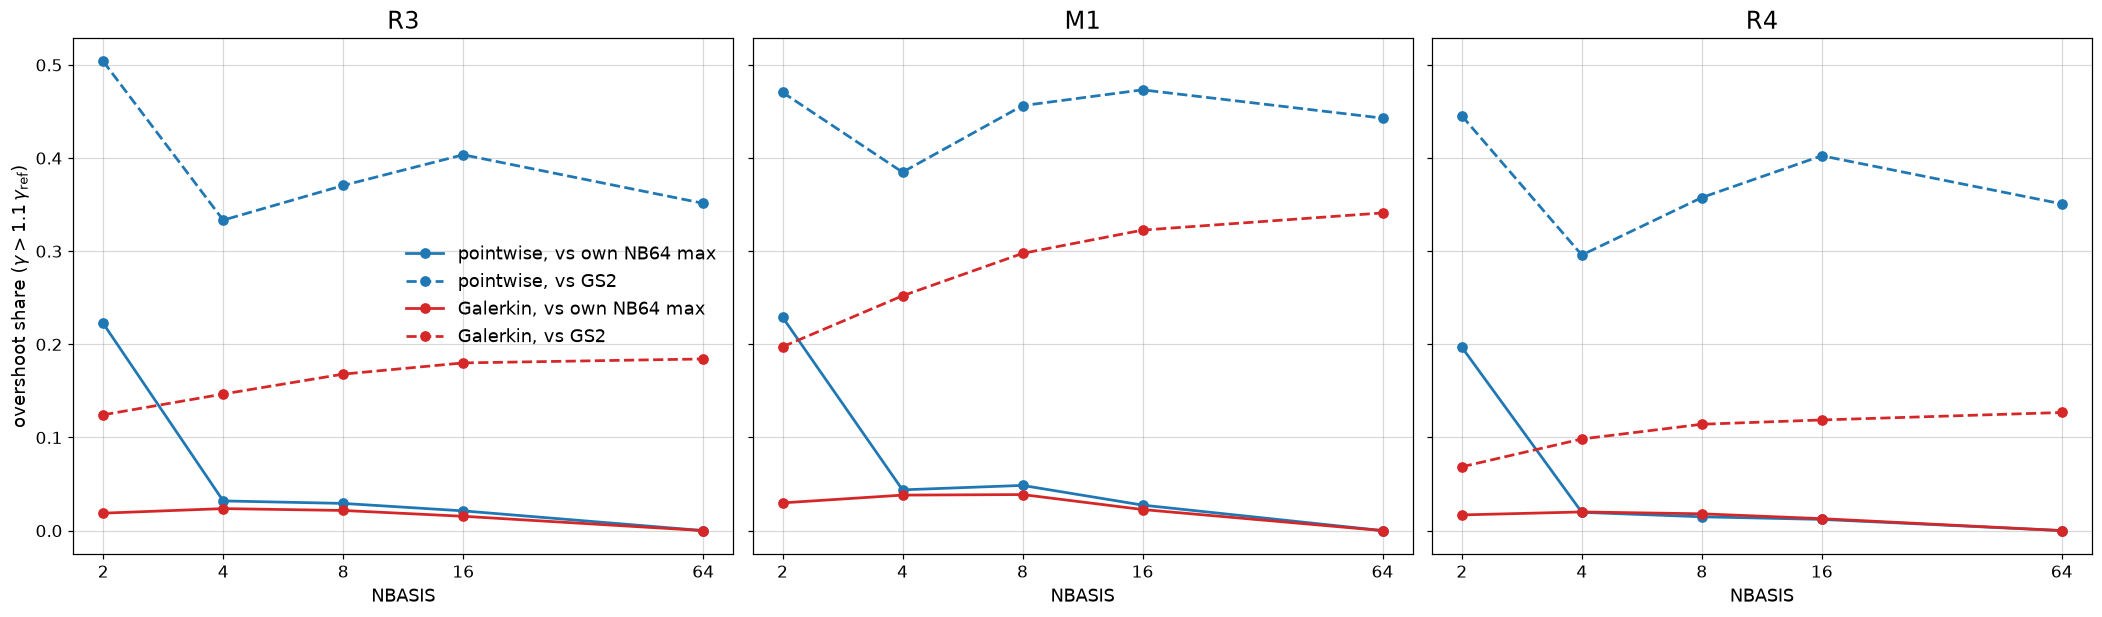

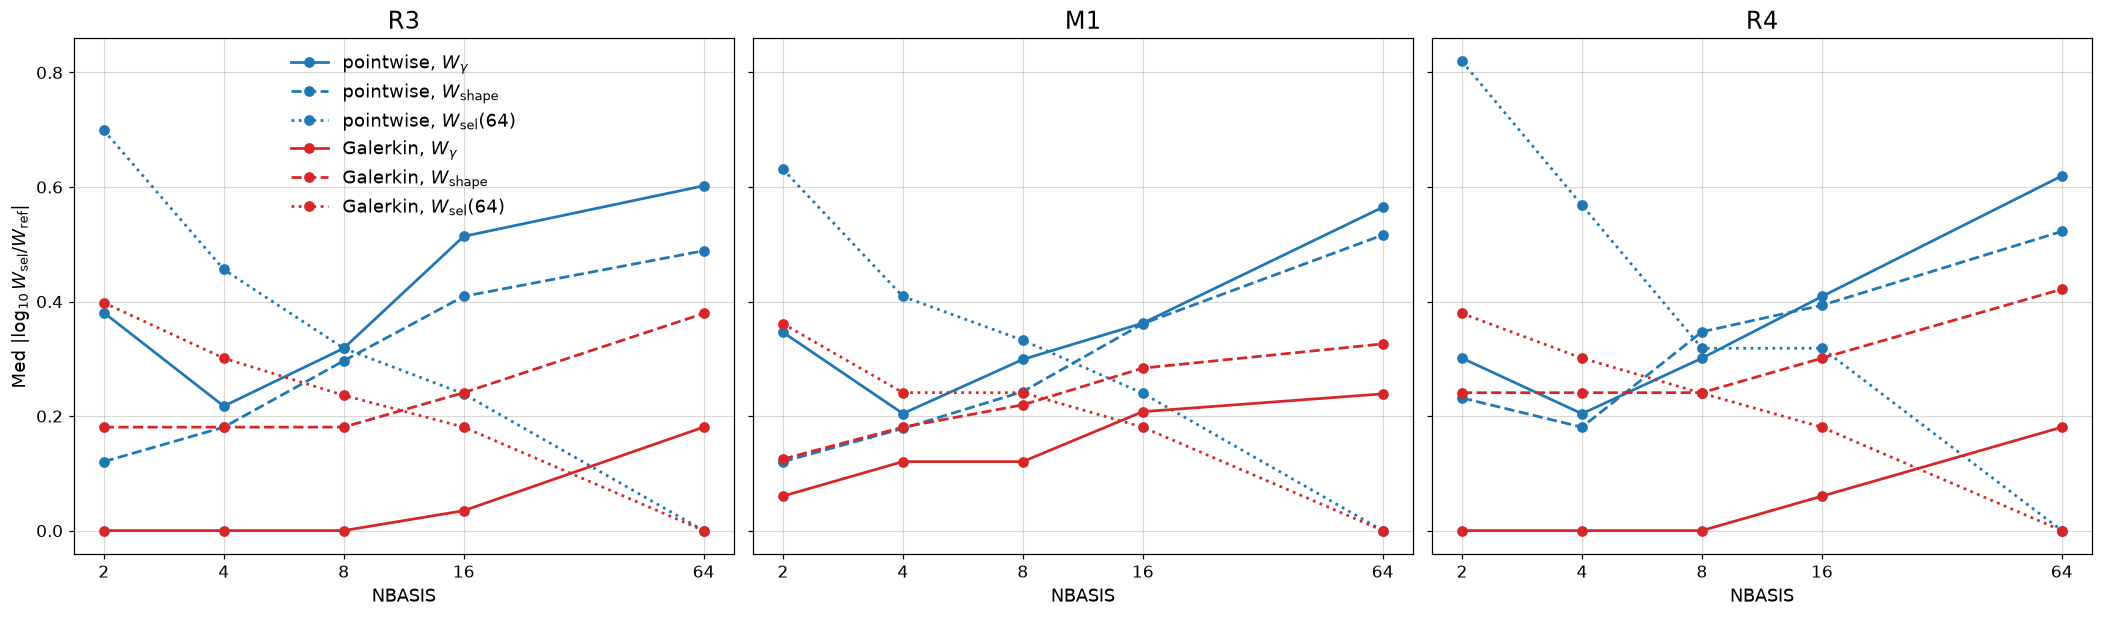

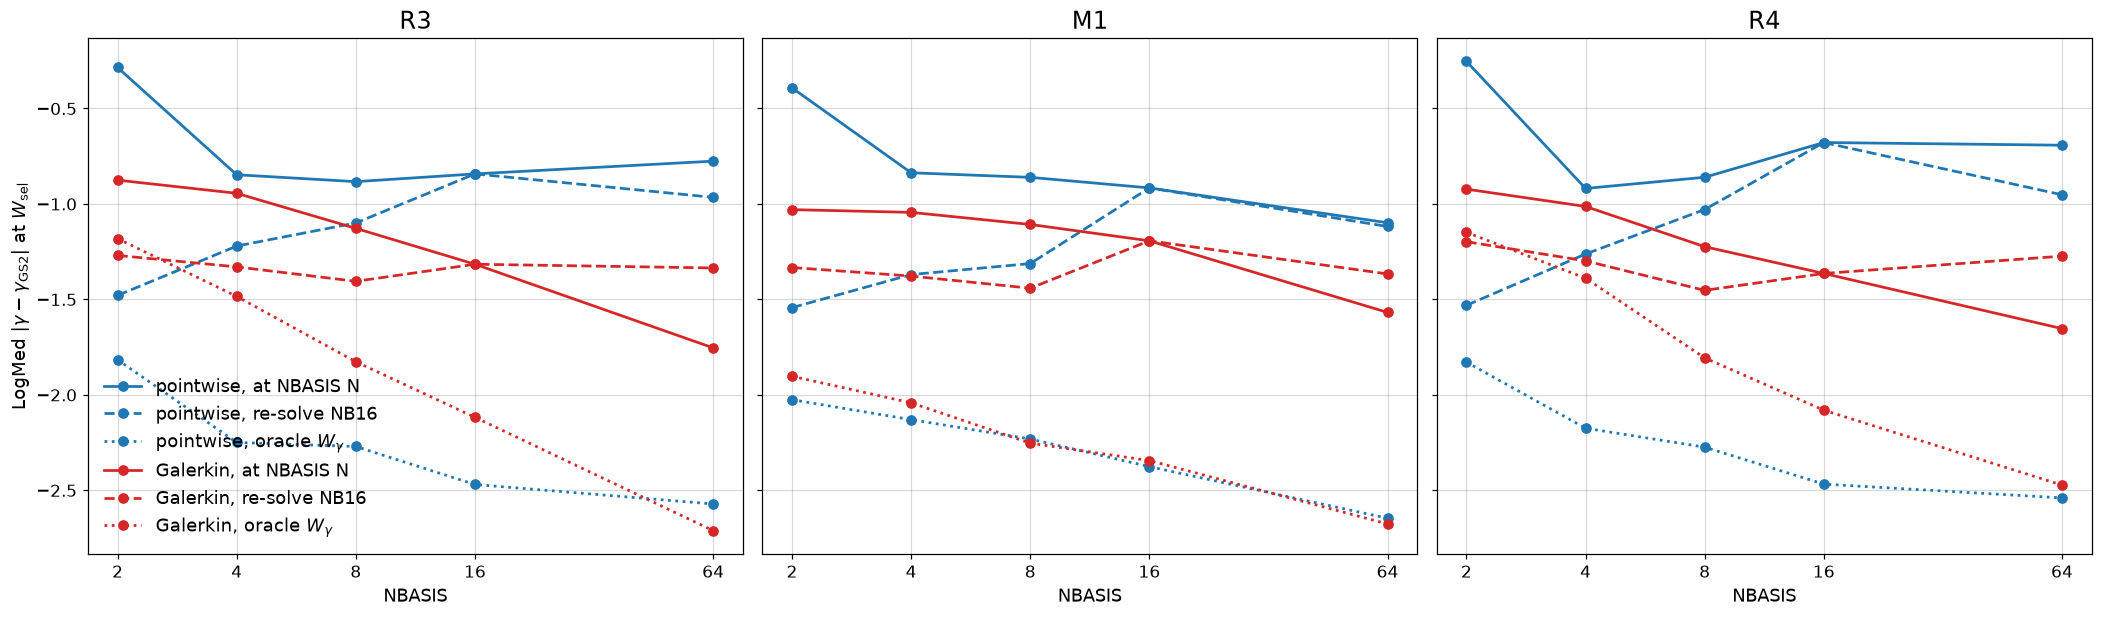

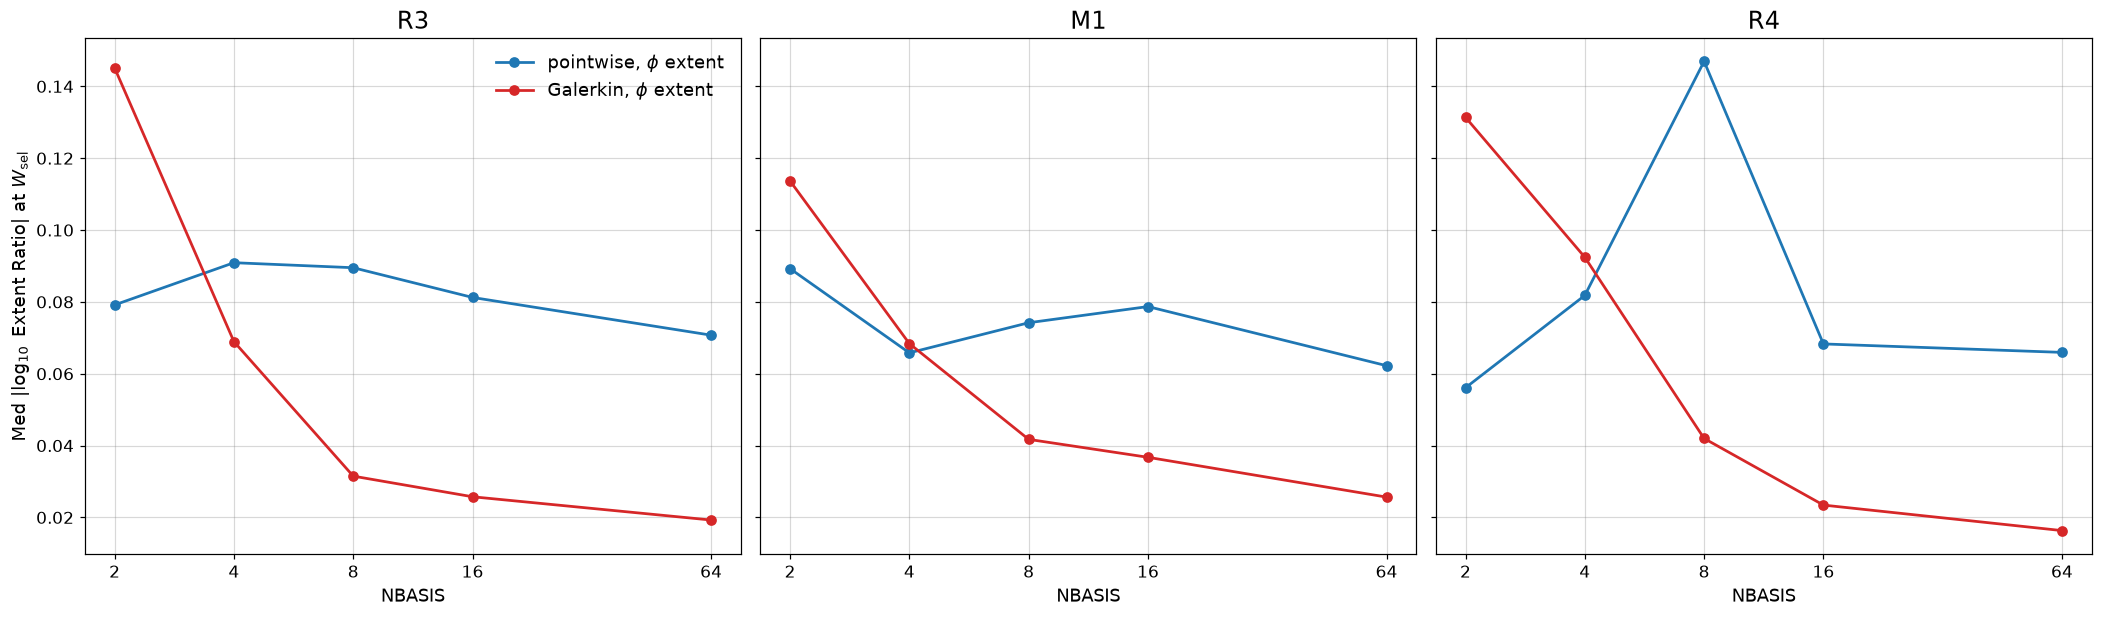

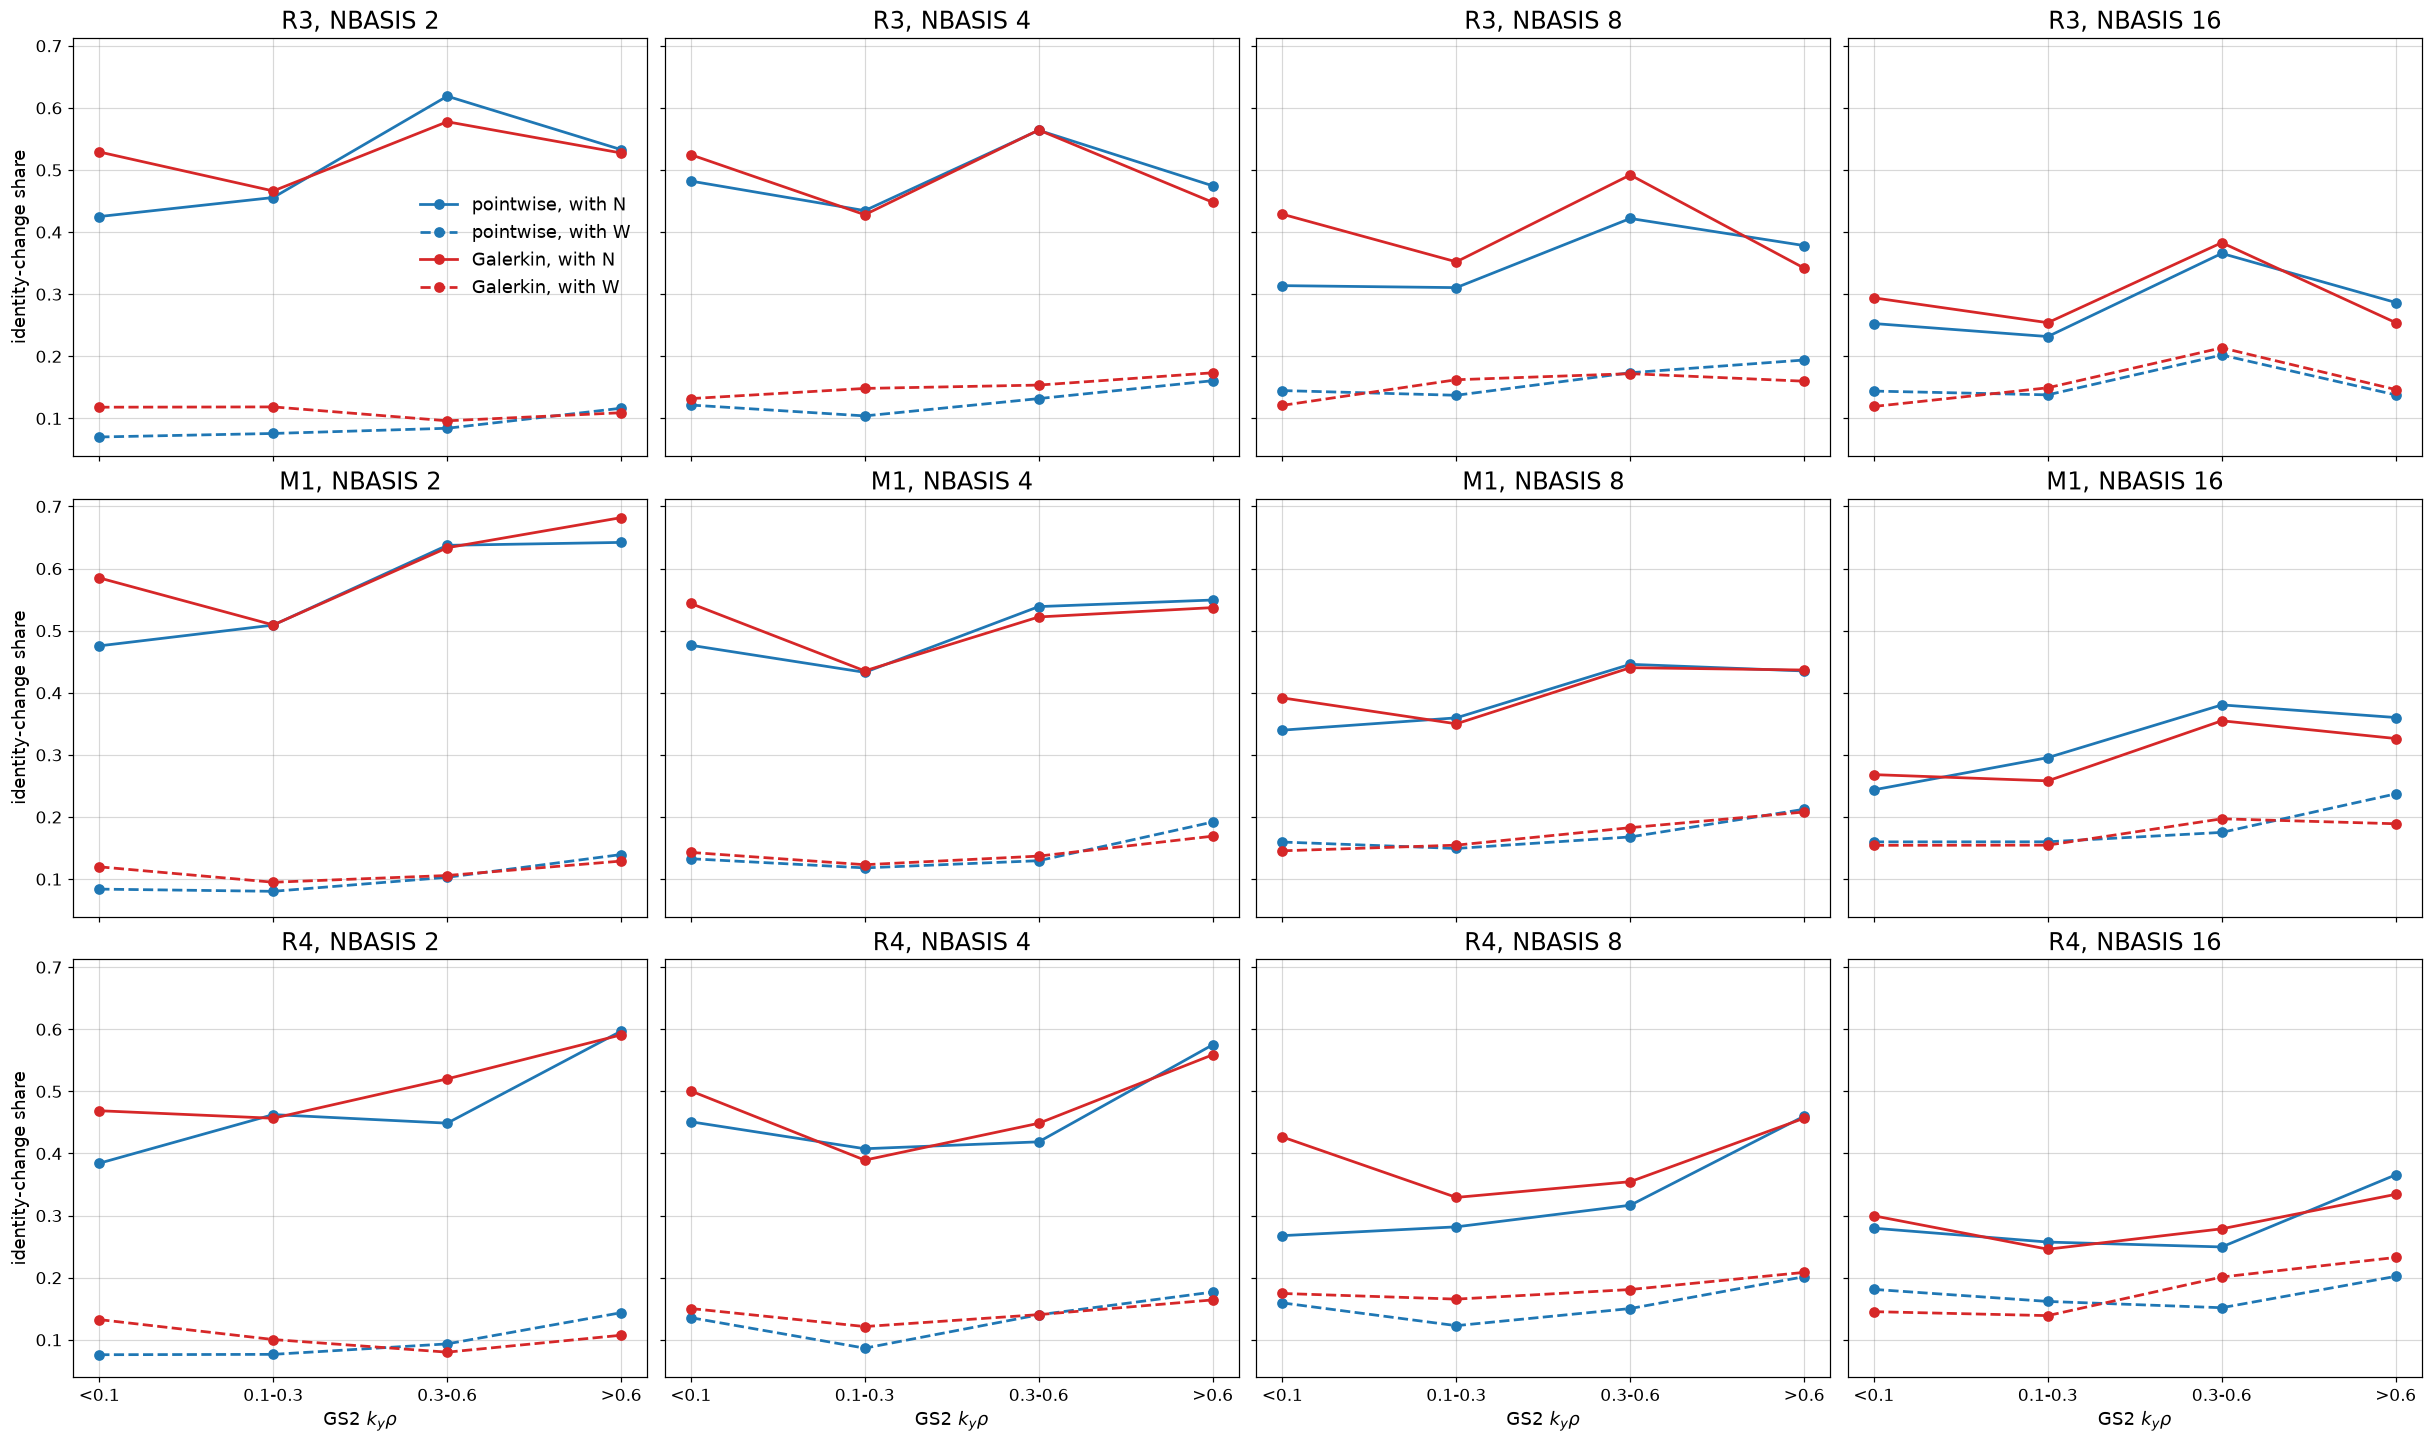

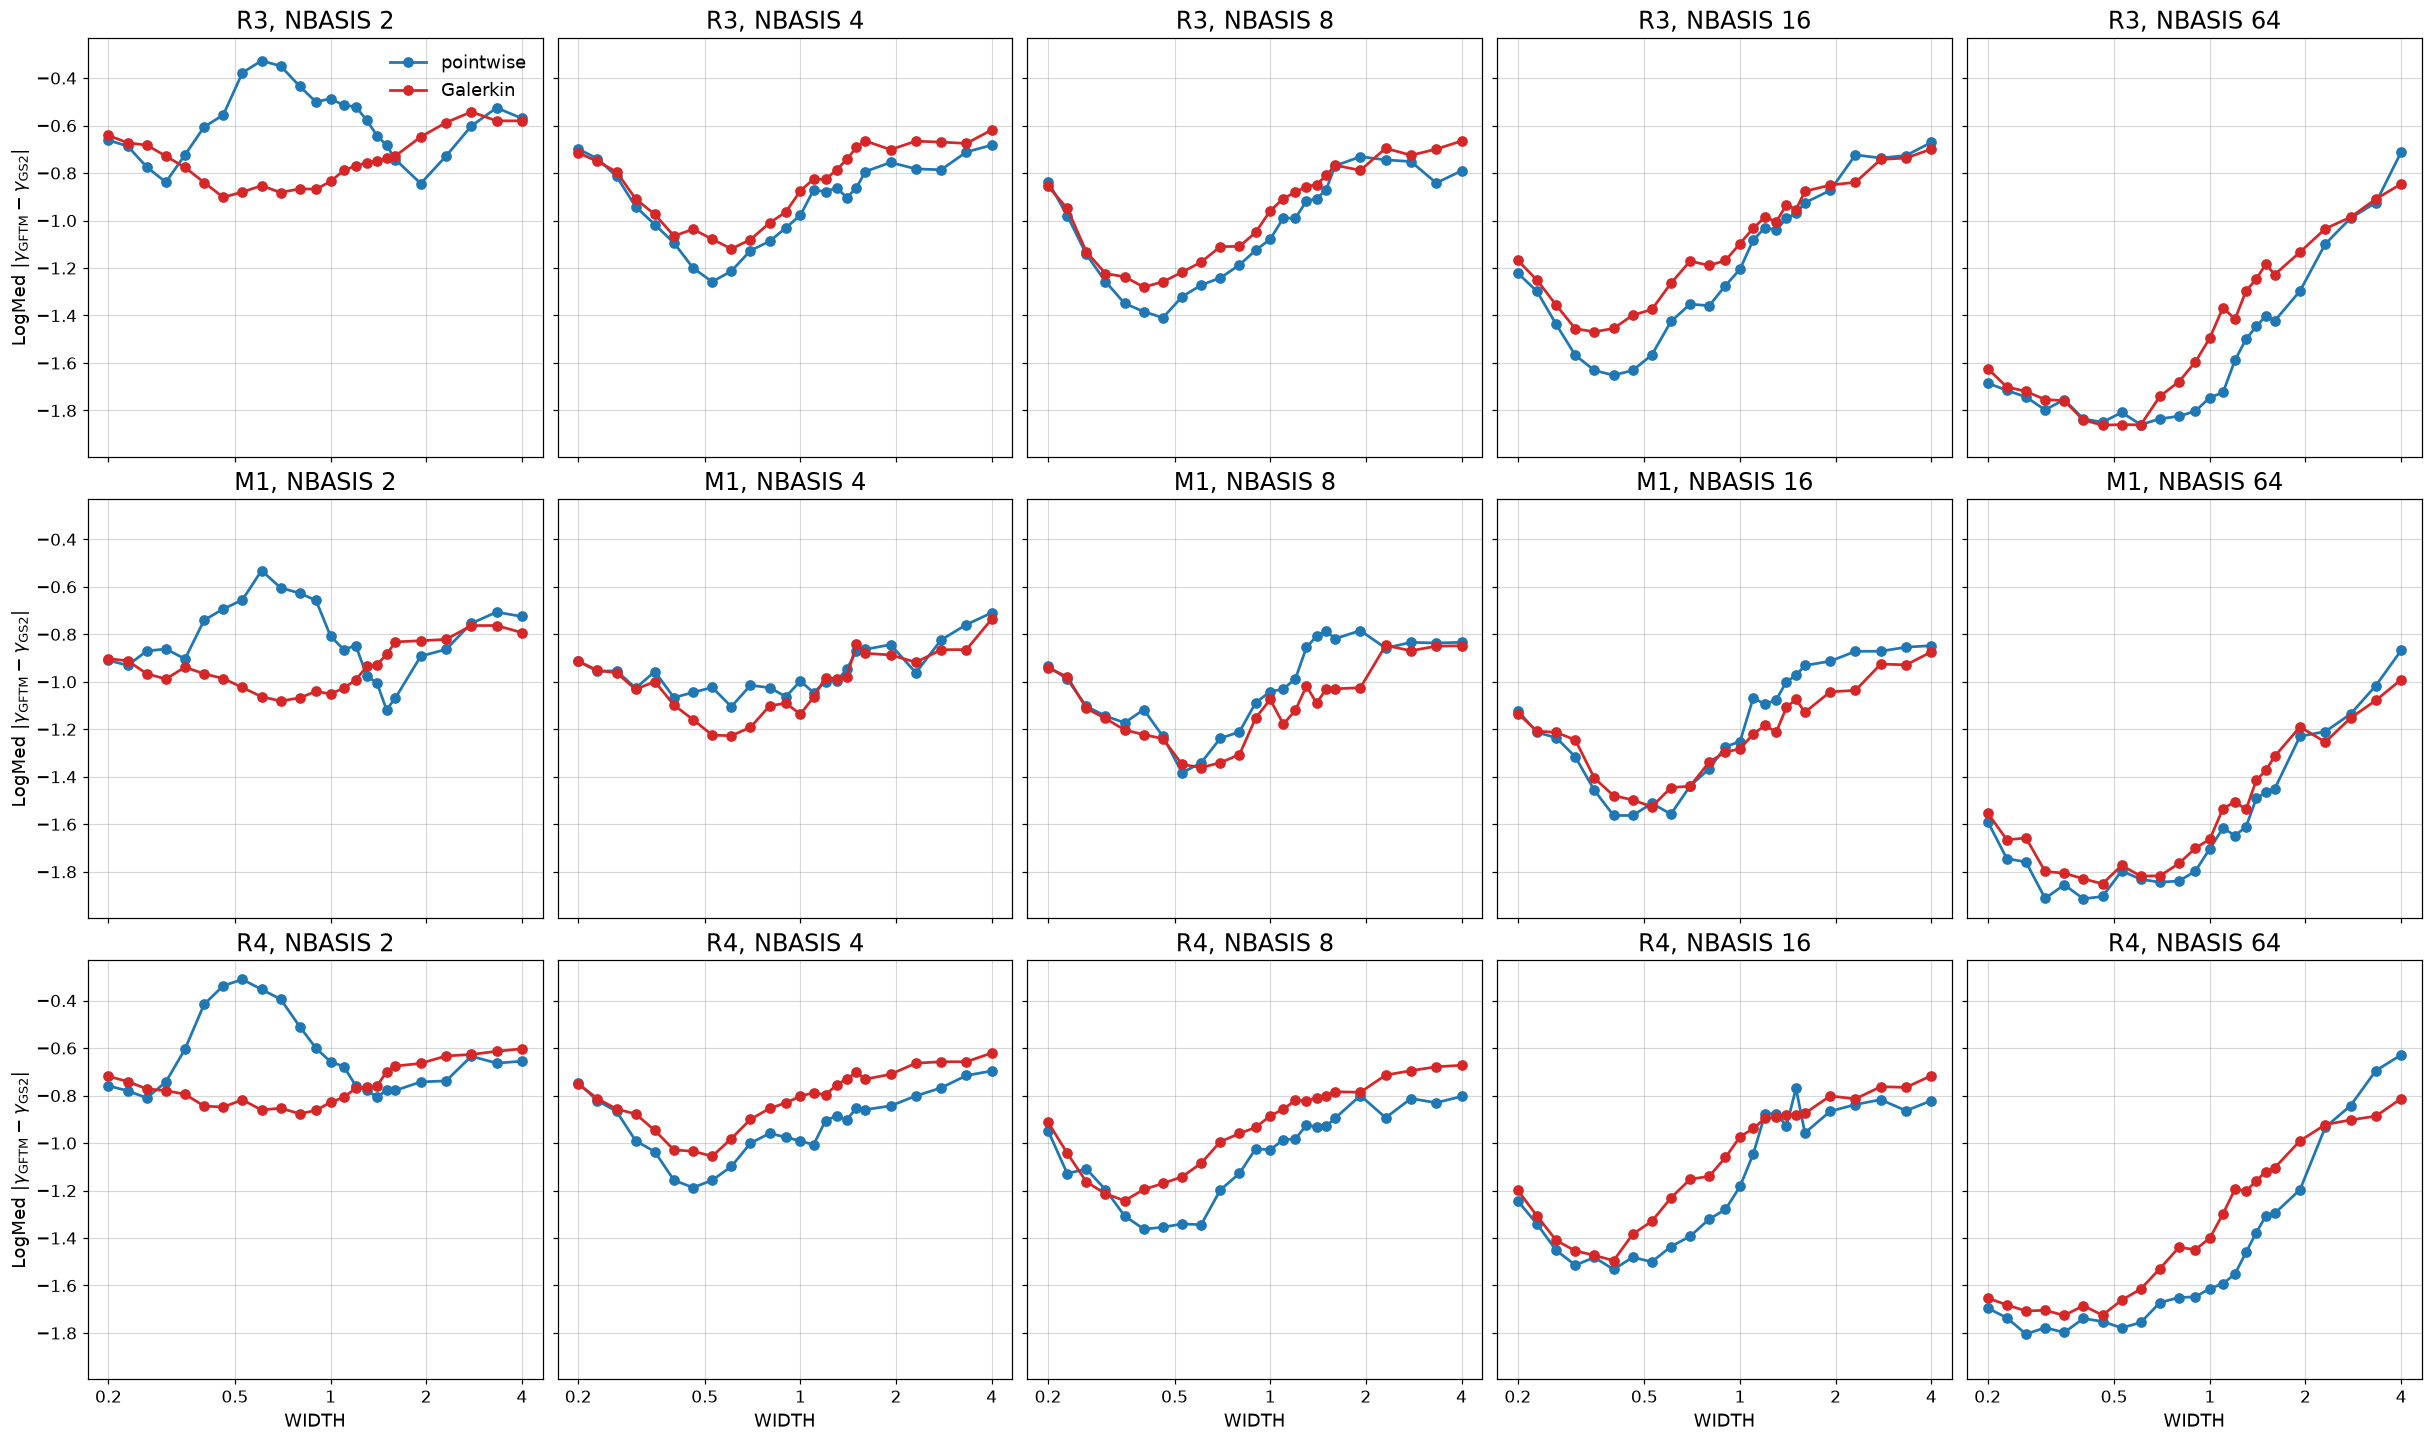

In [9]:
def per_case(table, styles, ylabel):
    fig, axes = plt.subplots(1, len(cases), figsize=(19, 5.5), sharex=True, sharey=True, squeeze=False)
    for ax, case in zip(axes[0], cases):
        for arm in arms:
            d = table[(table.case == case) & (table.arm == arm)].sort_values("nbasis")
            for column, (ls, label) in styles.items():
                ax.plot(d.nbasis, d[column], color=arm_colours[arm], ls=ls, marker="o",
                        label=f"{arms[arm]}, {label}" if case == cases[0] else None)
        ax.set(xscale="log", xlabel="NBASIS")
        ax.set_title(case, fontsize=fs_title)
        log_xticks(ax, nbasis_all)
    axes[0, 0].set_ylabel(ylabel)
    axes[0, 0].legend(fontsize=fs_legend)
    plt.show()
    return fig


fig1 = per_case(overshoot, {"overshoot_own": ("-", "vs own NB64 max"), "overshoot_gs2": ("--", "vs GS2")},
                r"overshoot share ($\gamma > 1.1\,\gamma_{\rm ref}$)")
fig2 = per_case(width_selection, {"to_w_gamma": ("-", r"$W_\gamma$"), "to_w_shape": ("--", r"$W_{\rm shape}$"),
                                  "to_w_sel64": (":", r"$W_{\rm sel}(64)$")}, r"Med $|\log_{10} W_{\rm sel}/W_{\rm ref}|$")
fig3 = per_case(accuracy, {"logmed_gamma": ("-", "at NBASIS N"), "two_stage_16": ("--", "re-solve NB16"), "oracle": (":", r"oracle $W_\gamma$")},
                r"LogMed $|\gamma-\gamma_{\rm GS2}|$ at $W_{\rm sel}$")
fig3b = per_case(accuracy, {"extent_ratio": ("-", r"$\phi$ extent")}, r"Med $|\log_{10}$ Extent Ratio$|$ at $W_{\rm sel}$")

fig4, axes4 = plt.subplots(len(cases), len(nbasis_low), figsize=(22, 13), sharex=True, sharey=True, squeeze=False)
for r, case in enumerate(cases):
    for j, nbasis in enumerate(nbasis_low):
        ax = axes4[r, j]
        for arm in arms:
            for comparison, ls in (("with_N", "-"), ("with_W", "--")):
                d = identity[(identity.case == case) & (identity.arm == arm) & (identity.nbasis == nbasis) &
                             (identity.comparison == comparison) & (identity.ky != "all")]
                ax.plot(range(len(ky_labels)), d["any"], color=arm_colours[arm], ls=ls, marker="o",
                        label=f"{arms[arm]}, {comparison.replace('_', ' ')}" if (r, j) == (0, 0) else None)
        ax.set_title(f"{case}, NBASIS {nbasis}", fontsize=fs_title)
        ax.set_xticks(range(len(ky_labels)), ky_labels)
        if r == len(cases) - 1:
            ax.set_xlabel(r"GS2 $k_y\rho$")
    axes4[r, 0].set_ylabel("identity-change share")
axes4[0, 0].legend(fontsize=fs_legend)
plt.show()

rows = []
for case in cases:
    for (case_, arm, nbasis, width), entry in gftm.items():
        if case_ == case:
            rows.append(dict(case=case, arm=arm, nb=nbasis, W=width,
                             gamma_logmed=np.log10(np.median(np.abs(entry["gamma"] - gs2[case]["gamma"])))))
acc = pd.DataFrame(rows).sort_values(["case", "arm", "nb", "W"])
fig5, axes5 = plt.subplots(len(cases), len(nbasis_all), figsize=(22, 13), sharex=True, sharey=True, squeeze=False)
for r, case in enumerate(cases):
    for j, nb in enumerate(nbasis_all):
        ax = axes5[r, j]
        for arm in arms:
            a = acc[(acc.case == case) & (acc.arm == arm) & (acc.nb == nb)]
            ax.plot(a.W, a.gamma_logmed, color=arm_colours[arm], label=arms[arm])
        ax.set(xscale="log")
        ax.set_title(f"{case}, NBASIS {nb}", fontsize=fs_title)
        if r == len(cases) - 1:
            ax.set_xlabel("WIDTH")
            log_xticks(ax, [0.2, 0.5, 1, 2, 4])
    axes5[r, 0].set_ylabel(r"LogMed $|\gamma_{\rm GFTM}-\gamma_{\rm GS2}|$")
axes5[0, 0].legend(fontsize=fs_legend)
plt.show()

## 5. Galerkin search vs fixed width (Fusion_PhD-qp5.25)

Question (user, 2026-10-27): can a Galerkin width search give better overall $\gamma$ or $\omega$ agreement with GS2 than a
fixed WIDTH, and at what measured cost? No new runs: every recipe is assembled from the leaves above. Each sample is scored
against its own GS2 $\gamma$ and $\omega$. **Sign convention:** pyro's, $\omega > 0$ in the ion diamagnetic direction, for
GFTM and GS2 alike.

**Recipes.**
- **Fixed width** (no search), both arms, NBASIS 8, 16, 64. The width must not be tuned on the samples it is scored on:
  - *LODO* (leave one database out): the width minimising LogMed $|\gamma - \gamma_{\rm GS2}|$ over the pooled samples of
    the other two databases, scored on the third;
  - *W 1.6*: the GFTM/GFS default 1.74 is not on the grid, so the nearest grid width (1.6, 0.036 dex away) stands in;
  - *in-sample bound*: the width minimising the error on the scored database itself. An upper bound, never a recipe.
- **Search**: $W_{\rm sel} = \arg\max_W \gamma(W, N_{\rm search})$ in the search arm, then the final answer at $W_{\rm sel}$
  from a final solve in either arm at $N_{\rm final} \in \{16, 64\}$, or no re-solve ($N_{\rm final} = N_{\rm search}$).
  Galerkin search at $N_{\rm search} \in \{4, 8, 16\}$; pointwise search at $\{2, 4, 8, 16\}$ for reference only. Coarser
  searches use every 2nd (12 widths) or every 4th (6 widths) grid width. A sample with no unstable mode at any searched
  width falls to the first searched width.
- **Pointwise NB2 caveat:** its max-$\gamma$ width (median near W 0.5-0.7) is a spurious overshoot (section 1, 56-72% of
  samples overshoot at some width), which happens to sit near the width that suits GS2. Its re-solve accuracy is not
  evidence that the pointwise NB2 search finds the physical mode.

**Metrics**, per database and pooled. A sample with no unstable mode has $\gamma = 0$ and is given $\omega = 0$, so it
scores $|\omega_{\rm GS2}|$.
- LogMed $|\gamma - \gamma_{\rm GS2}|$ and LogMed $|\omega - \omega_{\rm GS2}|$ ($\log_{10}$ of the median);
- median relative errors $|\gamma - \gamma_{\rm GS2}|/\gamma_{\rm GS2}$ and $|\omega - \omega_{\rm GS2}|/|\omega_{\rm GS2}|$;
- `sign_mismatch`: the share of samples with an unstable GFTM mode whose $\omega$ sign differs from GS2's (a mode-identity
  failure); `no_mode`: the share with none;
- `extent_dex`: median $|\log_{10}({\rm Extent}_{\rm GFTM}/{\rm Extent}_{\rm GS2})|$ of $\phi$ (pyro `Extent`, 95%).

**Cost, measured.** Each GFTM run writes `out.gftm.localdump` when it starts and `out.gftm.run` when it ends; the
difference of their modification times is the run's wall time. The file system stores whole seconds, so one NBASIS
$\le 16$ run reads 0-3 s, but the mean over every run in a cell is not biased by the rounding. The cost of a recipe per
sample is $n_W\,\bar t(\mathrm{arm}_s, N_{\rm search}) + \bar t(\mathrm{arm}_f, N_{\rm final})$ (the second term is
dropped without a re-solve); a fixed width costs one solve.

**Paired comparison.** Per sample, does the search's $|\mathrm{err}|$ beat the fixed width's? Ties (both pick the same
width) are counted separately. 95% CI from 2000 bootstrap resamples of the samples.

In [10]:
# wall time of every run, from its own files (see above); runs in the Slurm job, not on the login node
rows = []
for case in cases:
    for leaf in sorted((gftm_root / case / "kbm_free").glob("gal*_nb*")):
        arm, nbasis = leaf.name[3], int(re.search(r"_nb(\d+)_", leaf.name).group(1))
        for name in names[case]:
            rows.append(dict(case=case, arm=arm, nbasis=nbasis,
                             seconds=(leaf / name / "out.gftm.run").stat().st_mtime - (leaf / name / "out.gftm.localdump").stat().st_mtime))
timing = pd.DataFrame(rows)
solve_seconds = timing.groupby(["arm", "nbasis"]).seconds.mean()
timing_summary = timing.groupby(["arm", "nbasis"]).seconds.describe(percentiles=[0.5]).reset_index()
print("seconds per GFTM run, all databases:")
print(timing_summary.round(2).to_string(index=False))
print(timing.pivot_table(index="nbasis", columns=["case", "arm"], values="seconds").round(2).to_string())

seconds per GFTM run, all databases:
arm  nbasis   count  mean  std  min  50%  max
  F       2 12840.0  0.02 0.14  0.0  0.0  2.0
  F       4 12840.0  0.04 0.19  0.0  0.0  1.0
  F       8 12840.0  0.13 0.33  0.0  0.0  1.0
  F      16 12840.0  0.77 0.43  0.0  1.0  2.0
  F      64 12840.0 44.96 8.92 27.0 45.0 69.0
  T       2 12840.0  0.02 0.13  0.0  0.0  1.0
  T       4 12840.0  0.03 0.18  0.0  0.0  1.0
  T       8 12840.0  0.13 0.34  0.0  0.0  2.0
  T      16 12840.0  0.78 0.42  0.0  1.0  2.0
  T      64 12840.0 43.33 7.69 25.0 43.0 63.0


case       M1            R3            R4       
arm         F      T      F      T      F      T
nbasis                                          
2        0.02   0.02   0.02   0.02   0.02   0.02
4        0.04   0.03   0.04   0.03   0.03   0.03
8        0.12   0.12   0.13   0.13   0.13   0.13
16       0.75   0.76   0.77   0.77   0.79   0.80
64      41.48  40.71  43.33  42.66  48.76  45.69


In [11]:
fixed_nbasis = [8, 16, 64]
search_grids = {24: slice(None), 12: slice(None, None, 2), 6: slice(None, None, 4)}
default_width_index = np.abs(np.log10(widths / 1.74)).argmin()     # 1.74 is not on the grid
print("stand-in for the default 1.74:", widths[default_width_index])


def at_width(case, arm, nbasis, width_index):
    # per-sample gamma, omega, extent of one solve at a per-sample grid-width index
    samples = np.arange(len(names[case]))
    return {quantity: stack(case, arm, nbasis, quantity)[width_index, samples] for quantity in ("gamma", "omega", "extent")}


recipes = {}        # label -> dict(family, final arm, cost per sample in s, {case: per-sample values})
chosen_widths = []
for arm in arms:
    for nbasis in fixed_nbasis:
        width_error = {case: np.abs(stack(case, arm, nbasis, "gamma") - gs2[case]["gamma"]) for case in cases}
        held_out = {case: np.median(np.hstack([width_error[other] for other in cases if other != case]), 1).argmin() for case in cases}
        in_sample = {case: np.median(width_error[case], 1).argmin() for case in cases}
        default = {case: default_width_index for case in cases}
        for family, choice in (("fixed LODO", held_out), ("fixed W 1.6", default), ("fixed in-sample bound", in_sample)):
            recipes[f"{arms[arm]} NB{nbasis}, {family}"] = dict(
                family=family, final_arm=arm, cost=solve_seconds[arm, nbasis],
                values={case: at_width(case, arm, nbasis, np.full(len(names[case]), choice[case])) for case in cases})
            chosen_widths += [dict(arm=arm, nbasis=nbasis, family=family, case=case, width=widths[choice[case]]) for case in cases]
print(pd.DataFrame(chosen_widths).pivot_table(index=["family", "arm", "nbasis"], columns="case", values="width").to_string())

w_selected = {}     # (search arm, N_search, n_W, case) -> per-sample selected width index
for search_arm, search_nbasis_list in (("T", [4, 8, 16]), ("F", [2, 4, 8, 16])):
    for search_nbasis in search_nbasis_list:
        for n_widths, grid in search_grids.items():
            grid_index = np.arange(len(widths))[grid]
            for case in cases:
                w_selected[search_arm, search_nbasis, n_widths, case] = grid_index[stack(case, search_arm, search_nbasis, "gamma")[grid].argmax(0)]
            finals = [(search_arm, search_nbasis)] + [(arm, nbasis) for arm in arms for nbasis in (16, 64) if (arm, nbasis) != (search_arm, search_nbasis)]
            for final_arm, final_nbasis in finals:
                resolve = (final_arm, final_nbasis) != (search_arm, search_nbasis)
                final = f"{arms[final_arm]} NB{final_nbasis}" if resolve else "no re-solve"
                recipes[f"{arms[search_arm]} search NB{search_nbasis} ({n_widths} W) -> {final}"] = dict(
                    family=f"{arms[search_arm]} search", final_arm=final_arm, n_widths=n_widths,
                    cost=n_widths * solve_seconds[search_arm, search_nbasis] + resolve * solve_seconds[final_arm, final_nbasis],
                    values={case: at_width(case, final_arm, final_nbasis, w_selected[search_arm, search_nbasis, n_widths, case]) for case in cases})


def errors(values, case_list):
    # per-sample |gamma err|, |omega err| (no unstable mode -> omega 0), and the GFTM arrays, over the listed databases
    gamma = np.concatenate([values[case]["gamma"] for case in case_list])
    omega = np.nan_to_num(np.concatenate([values[case]["omega"] for case in case_list]))
    gamma_gs2 = np.concatenate([gs2[case]["gamma"] for case in case_list])
    omega_gs2 = np.concatenate([gs2[case]["omega"] for case in case_list])
    return np.abs(gamma - gamma_gs2), np.abs(omega - omega_gs2), gamma, omega, gamma_gs2, omega_gs2


rows = []
for label, recipe in recipes.items():
    for database in cases + ["pooled"]:
        case_list = cases if database == "pooled" else [database]
        gamma_error, omega_error, gamma, omega, gamma_gs2, omega_gs2 = errors(recipe["values"], case_list)
        extent = np.concatenate([recipe["values"][case]["extent"] for case in case_list])
        extent_gs2 = np.concatenate([gs2[case]["extent"] for case in case_list])
        unstable = gamma > 0
        rows.append(dict(recipe=label, family=recipe["family"], database=database, cost_s=recipe["cost"],
                         logmed_gamma=np.log10(np.median(gamma_error)), logmed_omega=np.log10(np.median(omega_error)),
                         rel_gamma=np.median(gamma_error / gamma_gs2), rel_omega=np.median(omega_error / np.abs(omega_gs2)),
                         sign_mismatch=np.mean(np.sign(omega[unstable]) != np.sign(omega_gs2[unstable])), no_mode=np.mean(~unstable),
                         extent_dex=np.nanmedian(np.abs(np.log10(extent / extent_gs2)))))
scores = pd.DataFrame(rows)
pooled = scores[scores.database == "pooled"].set_index("recipe")
# best of each family on pooled gamma; the in-sample bound is not a recipe
best_fixed = pooled[pooled.family.isin(["fixed LODO", "fixed W 1.6"])].logmed_gamma.idxmin()
best_search = pooled[pooled.family == "Galerkin search"].logmed_gamma.idxmin()
best_search_omega = pooled[pooled.family == "Galerkin search"].logmed_omega.idxmin()
print("best fixed:", best_fixed, "| best Galerkin search (gamma):", best_search, "| (omega):", best_search_omega)
columns = ["cost_s", "logmed_gamma", "logmed_omega", "rel_gamma", "rel_omega", "sign_mismatch", "no_mode", "extent_dex"]
print(pooled[pooled.family != "pointwise search"].sort_values("logmed_gamma")[["family"] + columns].round(3).to_string())
print("\nper database, the fixed recipes and the full-grid Galerkin searches:")
shown = scores[scores.family.str.startswith("fixed") | scores.recipe.str.contains(r"Galerkin search .*\(24 W\)")]
print(shown.pivot_table(index="recipe", columns="database", values=["logmed_gamma", "logmed_omega"]).round(2).to_string())

stand-in for the default 1.74: 1.6
case                                  M1      R3      R4
family                arm nbasis                        
fixed LODO            F   8       0.4595  0.5279  0.4595
                          16      0.4000  0.4000  0.4000
                          64      0.6063  0.3482  0.4595
                      T   8       0.3482  0.3482  0.5279
                          16      0.4000  0.4000  0.4000
                          64      0.4595  0.4595  0.4595
fixed W 1.6           F   8       1.6000  1.6000  1.6000
                          16      1.6000  1.6000  1.6000
                          64      1.6000  1.6000  1.6000
                      T   8       1.6000  1.6000  1.6000
                          16      1.6000  1.6000  1.6000
                          64      1.6000  1.6000  1.6000
fixed in-sample bound F   8       0.5279  0.4595  0.4000
                          16      0.4000  0.4000  0.4000
                          64      0.4000  0.6063  0.2

best fixed:

 Galerkin NB64, fixed LODO | best Galerkin search (gamma): Galerkin search NB16 (6 W) -> pointwise NB64 | (omega): Galerkin search NB8 (24 W) -> pointwise NB64
                                                              family  cost_s  logmed_gamma  logmed_omega  rel_gamma  rel_omega  sign_mismatch  no_mode  extent_dex
recipe                                                                                                                                                            
pointwise NB64, fixed in-sample bound          fixed in-sample bound  44.959        -1.836        -1.723      0.058      0.099          0.093    0.000       0.017
Galerkin search NB16 (6 W) -> pointwise NB64         Galerkin search  49.630        -1.817        -1.731      0.061      0.104          0.075    0.002       0.020
Galerkin search NB8 (24 W) -> pointwise NB64         Galerkin search  48.047        -1.808        -1.746      0.065      0.105          0.064    0.004       0.019
Galerkin search NB16 (12 

In [12]:
rng = np.random.default_rng(0)


def paired(search, fixed, case_list):
    # share of samples where the search beats / ties the fixed width, per quantity, with a 2000-resample bootstrap CI
    result = {}
    for k, quantity in enumerate(("gamma", "omega")):
        search_error, fixed_error = errors(recipes[search]["values"], case_list)[k], errors(recipes[fixed]["values"], case_list)[k]
        wins = (search_error < fixed_error).astype(float)
        boot = rng.choice(wins, (2000, len(wins))).mean(1)
        result |= {f"{quantity}_beats": wins.mean(), f"{quantity}_ci_low": np.percentile(boot, 2.5),
                   f"{quantity}_ci_high": np.percentile(boot, 97.5), f"{quantity}_ties": np.mean(search_error == fixed_error)}
    return result


# every Galerkin search against the LODO fixed width with the same final solve, and the two best recipes against each other
rows = []
for label, recipe in recipes.items():
    if recipe["family"] == "Galerkin search":
        final = label.split("-> ")[1]
        final_nbasis = int(re.search(r"NB(\d+)", final if final != "no re-solve" else label).group(1))
        fixed = f"{arms[recipe['final_arm']]} NB{final_nbasis}, fixed LODO"
        if fixed in recipes:
            rows += [dict(search=label, fixed=fixed, database=database,
                          **paired(label, fixed, cases if database == "pooled" else [database])) for database in cases + ["pooled"]]
rows += [dict(search=best_search, fixed=best_fixed, database=database, best_vs_best=True,
              **paired(best_search, best_fixed, cases if database == "pooled" else [database])) for database in cases + ["pooled"]]
paired_scores = pd.DataFrame(rows)
print(paired_scores[paired_scores.best_vs_best == True].round(3).to_string(index=False))
print(paired_scores[(paired_scores.database == "pooled") & (paired_scores.search.str.contains(r"\(24 W\)"))]
      .drop(columns="best_vs_best").round(3).to_string(index=False))

# a search can only help if the best width varies from sample to sample: spread of the per-sample GS2-closest width
rows = []
for case in cases:
    for arm in arms:
        for nbasis in fixed_nbasis:
            w_gamma = widths[np.abs(stack(case, arm, nbasis, "gamma") - gs2[case]["gamma"]).argmin(0)]
            quantiles = np.percentile(w_gamma, [10, 25, 50, 75, 90])
            rows.append(dict(case=case, arm=arm, nbasis=nbasis, **dict(zip(["p10", "p25", "p50", "p75", "p90"], quantiles)),
                             iqr_dex=np.log10(quantiles[3] / quantiles[1]), at_edge=np.mean(np.isin(w_gamma, widths[[0, -1]]))))
w_gamma_spread = pd.DataFrame(rows)
print(w_gamma_spread.round(3).to_string(index=False))

                                      search                     fixed database  gamma_beats  gamma_ci_low  gamma_ci_high  gamma_ties  omega_beats  omega_ci_low  omega_ci_high  omega_ties best_vs_best
Galerkin search NB16 (6 W) -> pointwise NB64 Galerkin NB64, fixed LODO       R3        0.439         0.369          0.508       0.016        0.658         0.588          0.722       0.005         True
Galerkin search NB16 (6 W) -> pointwise NB64 Galerkin NB64, fixed LODO       M1        0.557         0.479          0.636       0.000        0.621         0.543          0.700       0.007         True
Galerkin search NB16 (6 W) -> pointwise NB64 Galerkin NB64, fixed LODO       R4        0.543         0.476          0.615       0.010        0.457         0.389          0.524       0.005         True
Galerkin search NB16 (6 W) -> pointwise NB64 Galerkin NB64, fixed LODO   pooled        0.510         0.465          0.553       0.009        0.570         0.527          0.611       0.006         

## Figures 6-10

- fig6 / fig7: per sample, GFTM against GS2 for $\gamma$ (log axes) and $\omega$ (linear); left the best fixed-width
  recipe (LODO or W 1.6, best pooled LogMed $|\gamma$ err$|$), right the best Galerkin-search recipe; one row per database.
  Samples with no unstable GFTM mode ($\gamma = 0$) are off the log axes of fig6.
- fig8: paired per-sample errors, $|\mathrm{err}|$ of the best fixed width (x) against the best Galerkin search (y),
  log-log; the title gives the share below $y = x$ (the search is better).
- fig9 (the answer figure): pooled LogMed error against the measured cost per sample, one point per recipe. Squares fixed
  width (open: the in-sample bound), circles Galerkin search (size: 24/12/6 widths), faint triangles pointwise search
  (24 widths); colour = arm of the final solve.
- fig10 (fig5 format): fixed-width $\phi$ extent error, median $|\log_{10}({\rm Extent}_{\rm GFTM}/{\rm Extent}_{\rm GS2})|$
  against WIDTH; dotted red = the Galerkin max-$\gamma$ search at $W_{\rm sel}(N)$, no re-solve (the fig3b values).

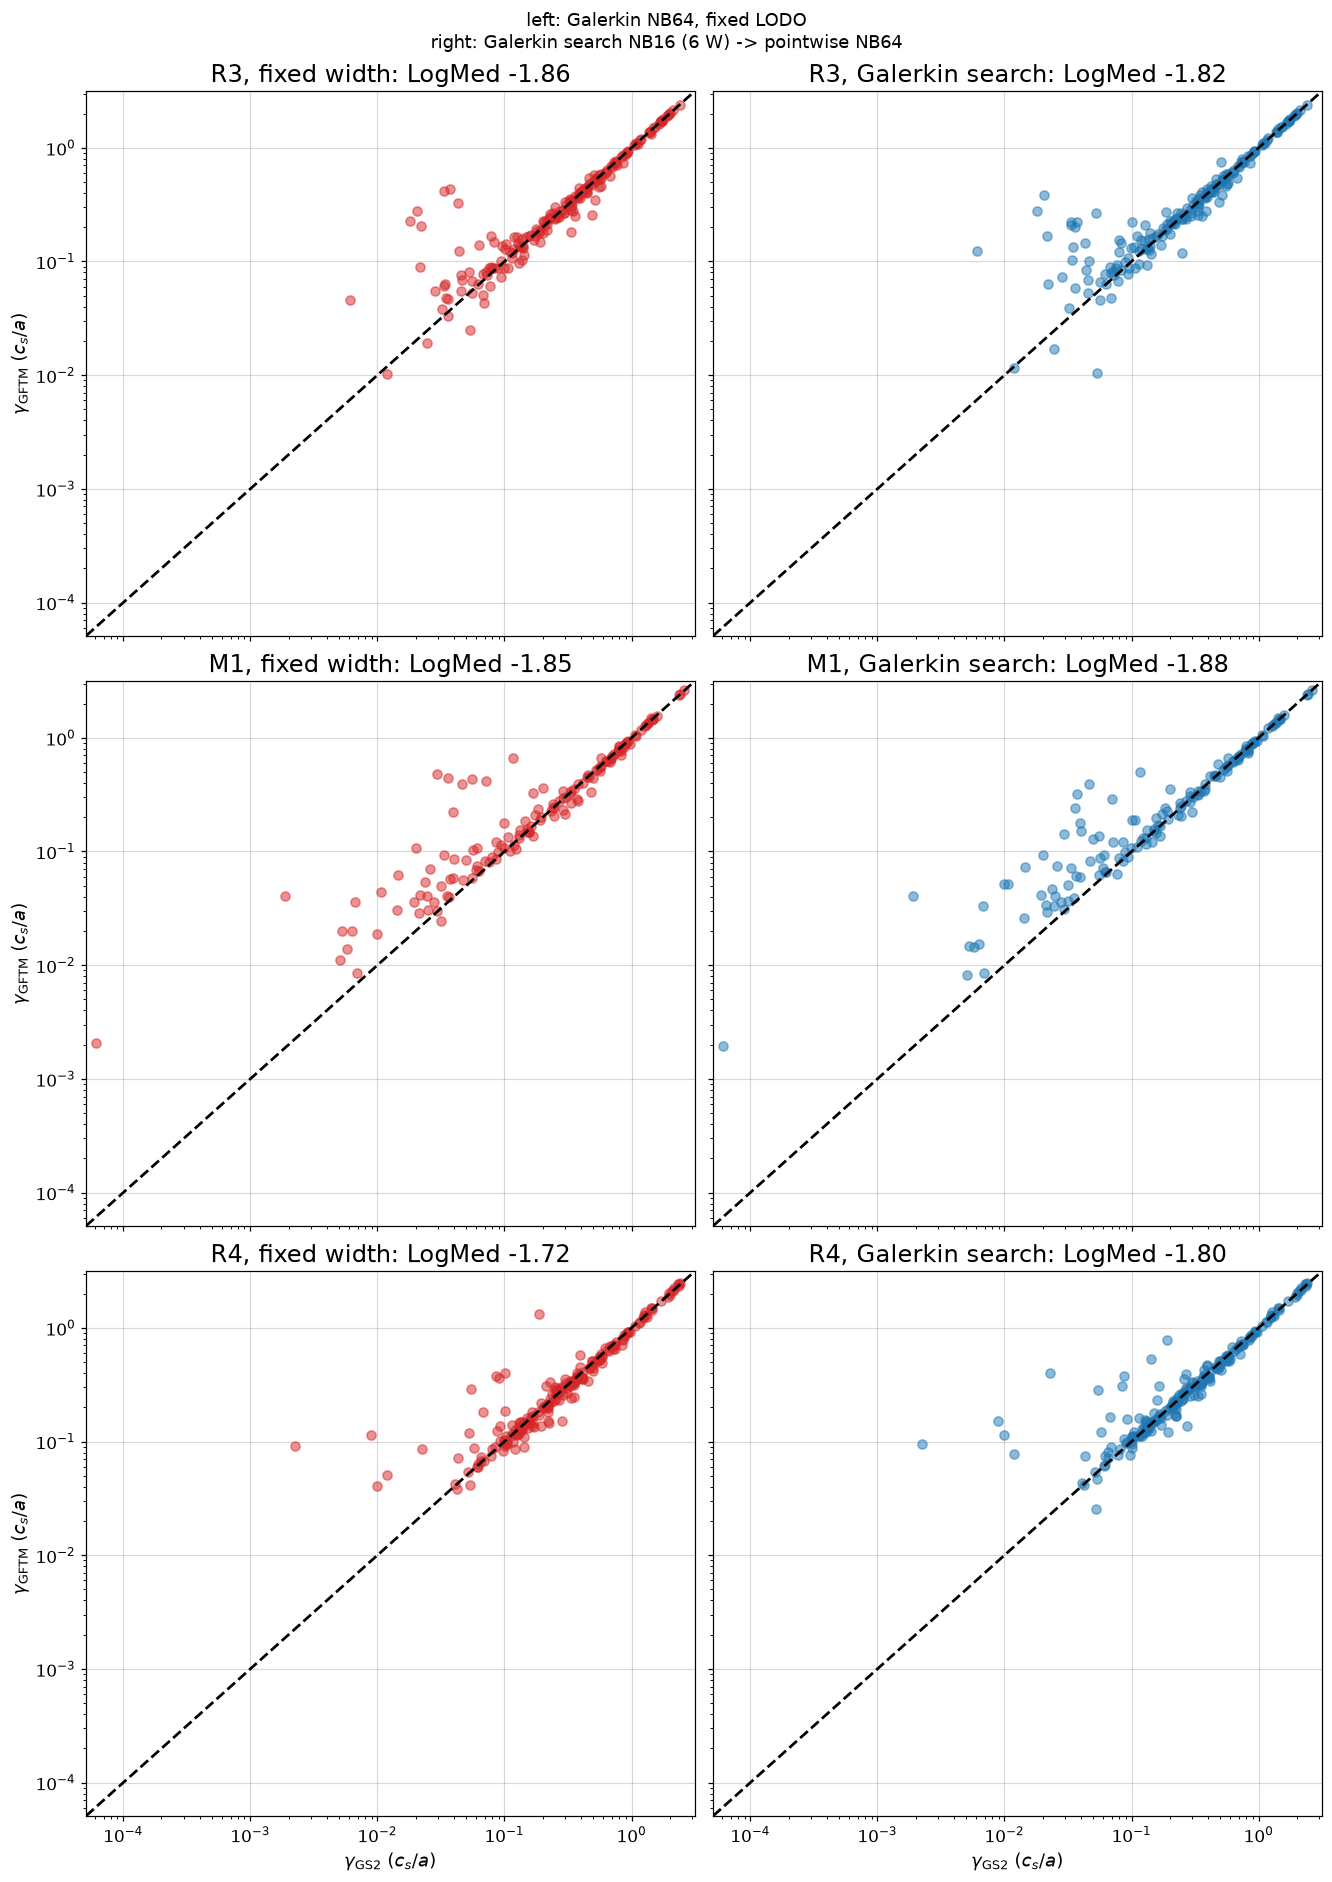

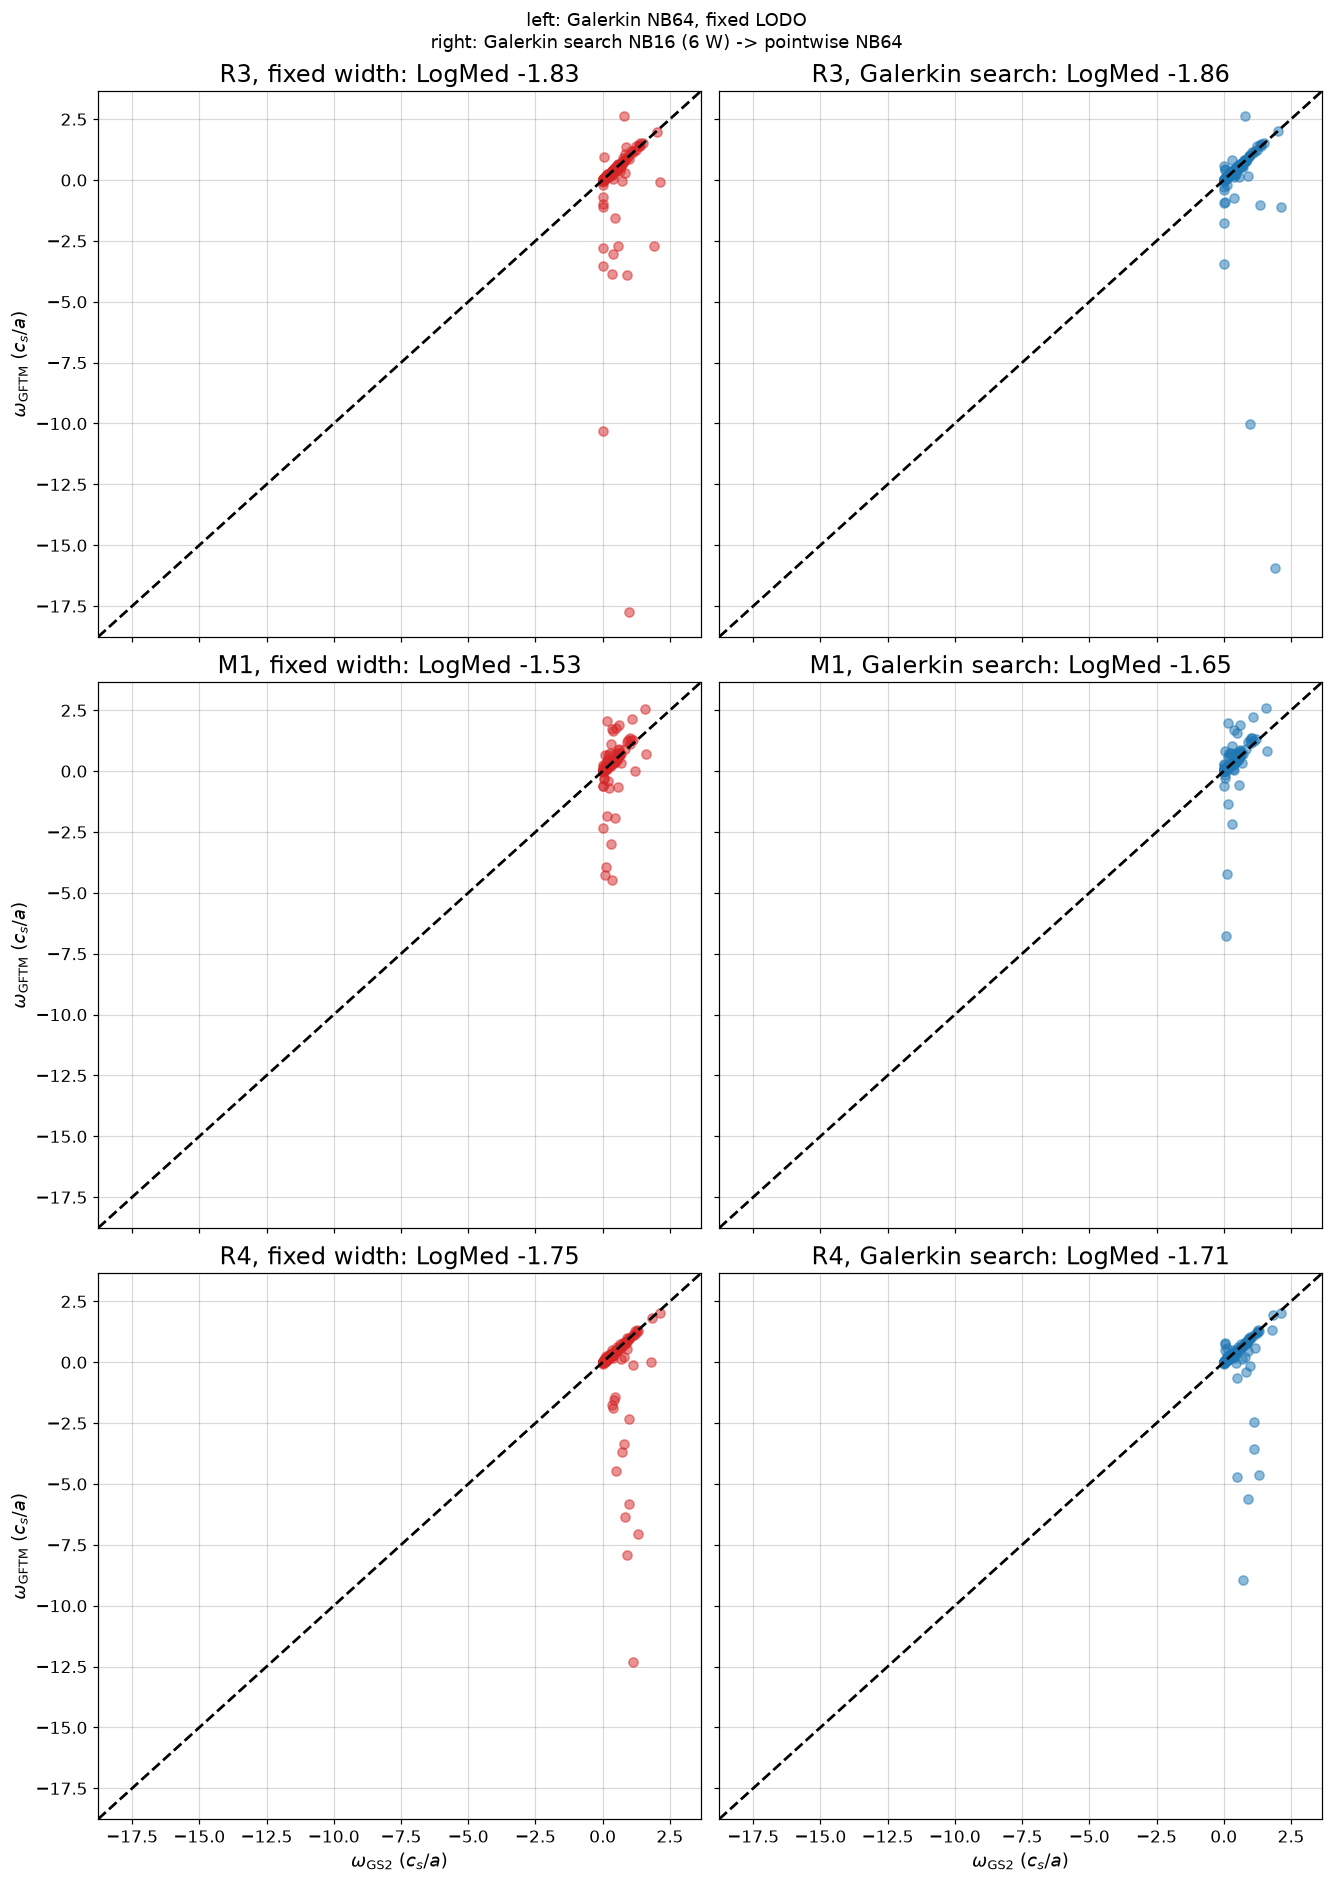

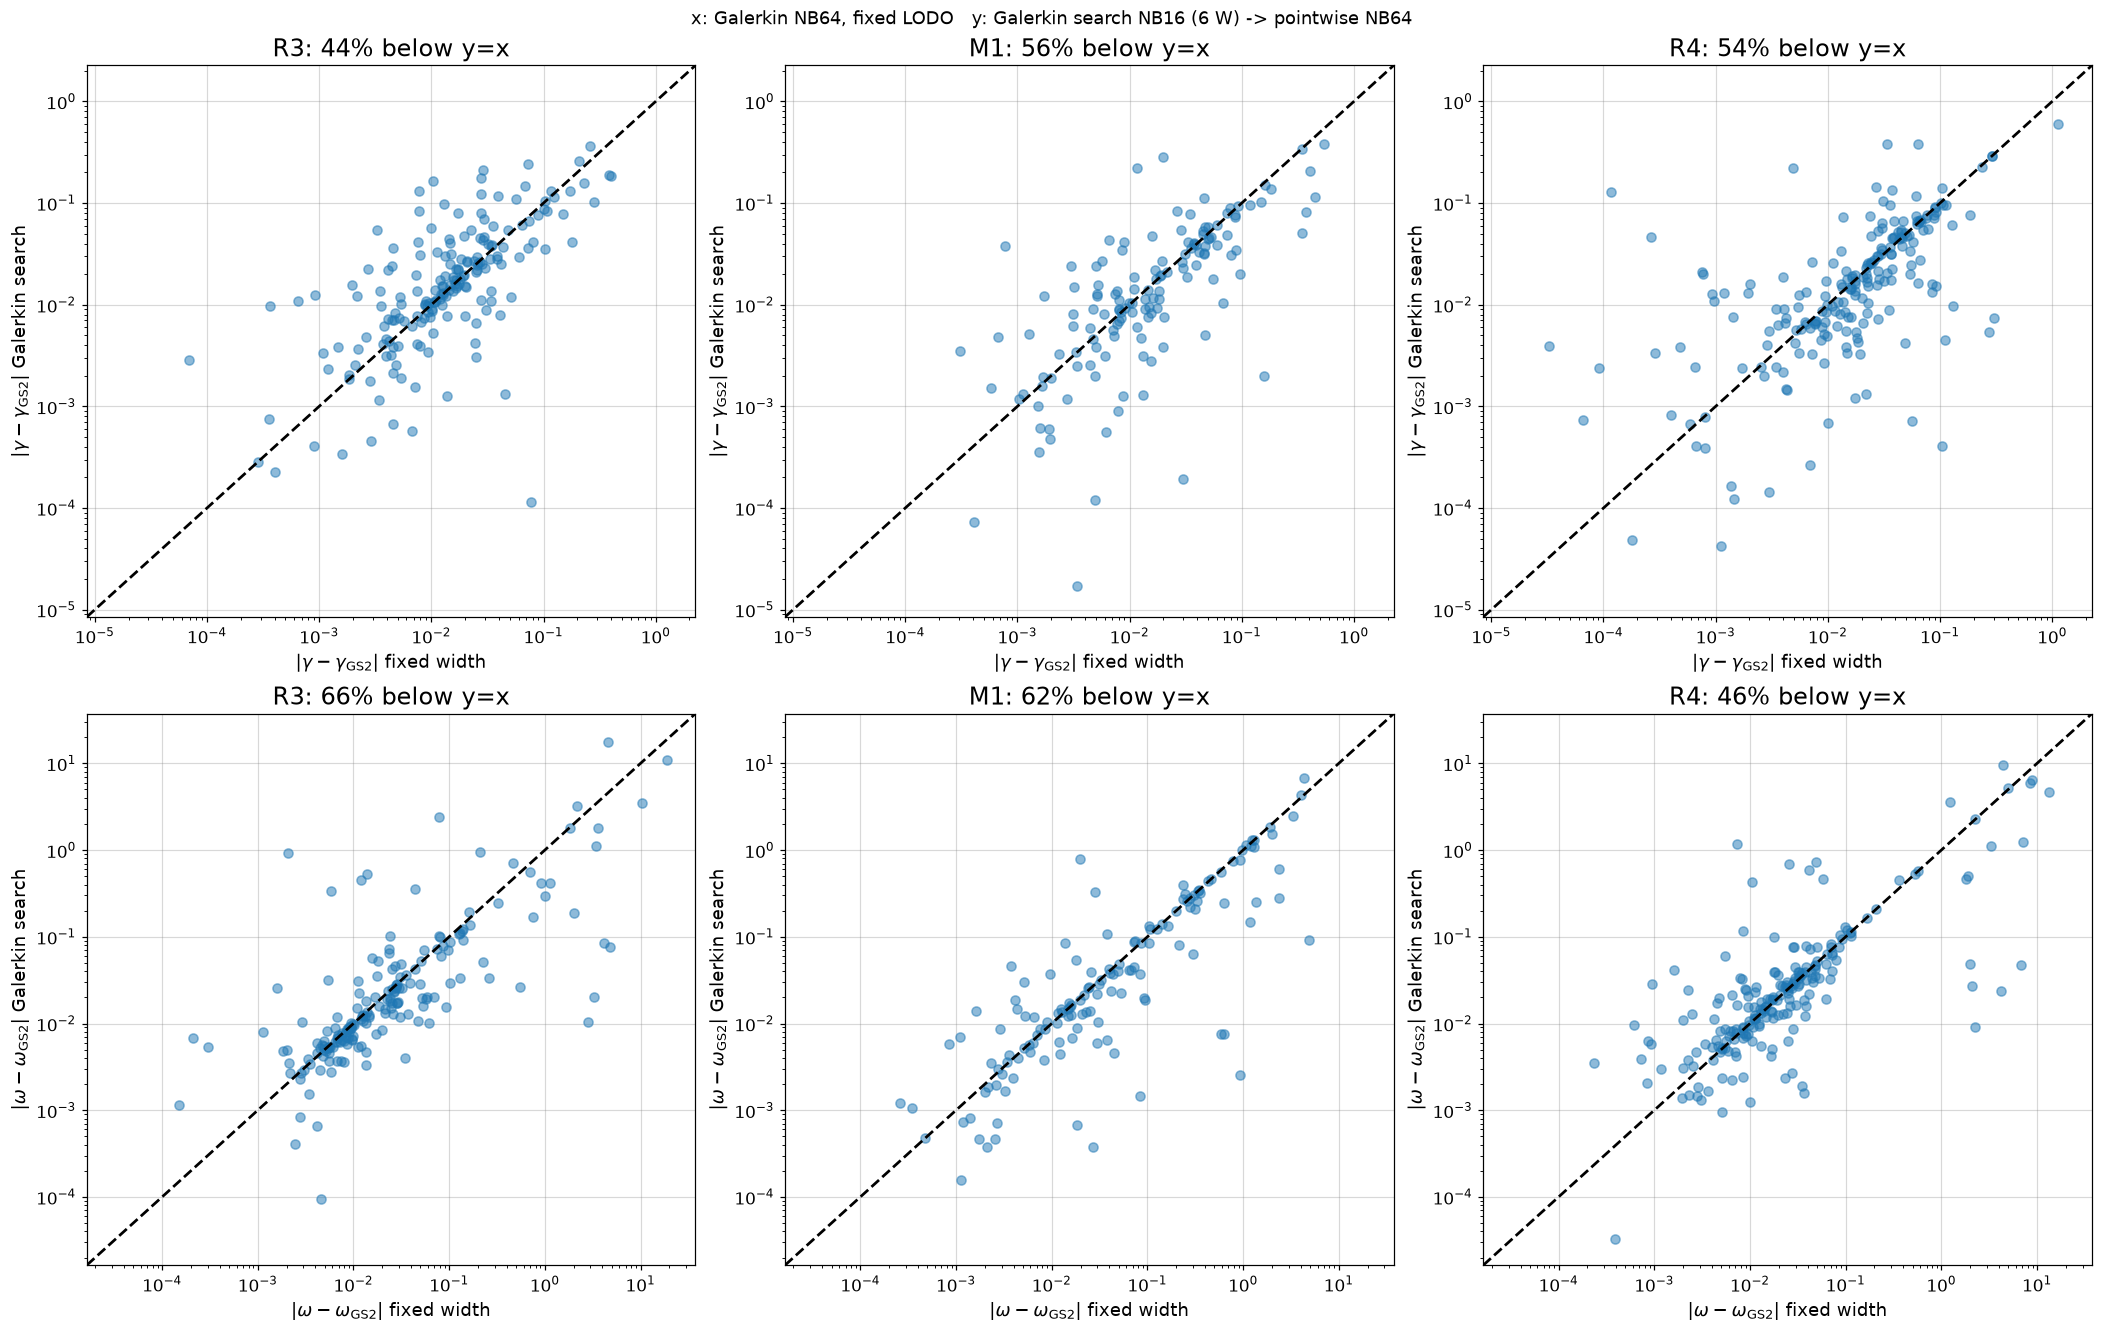

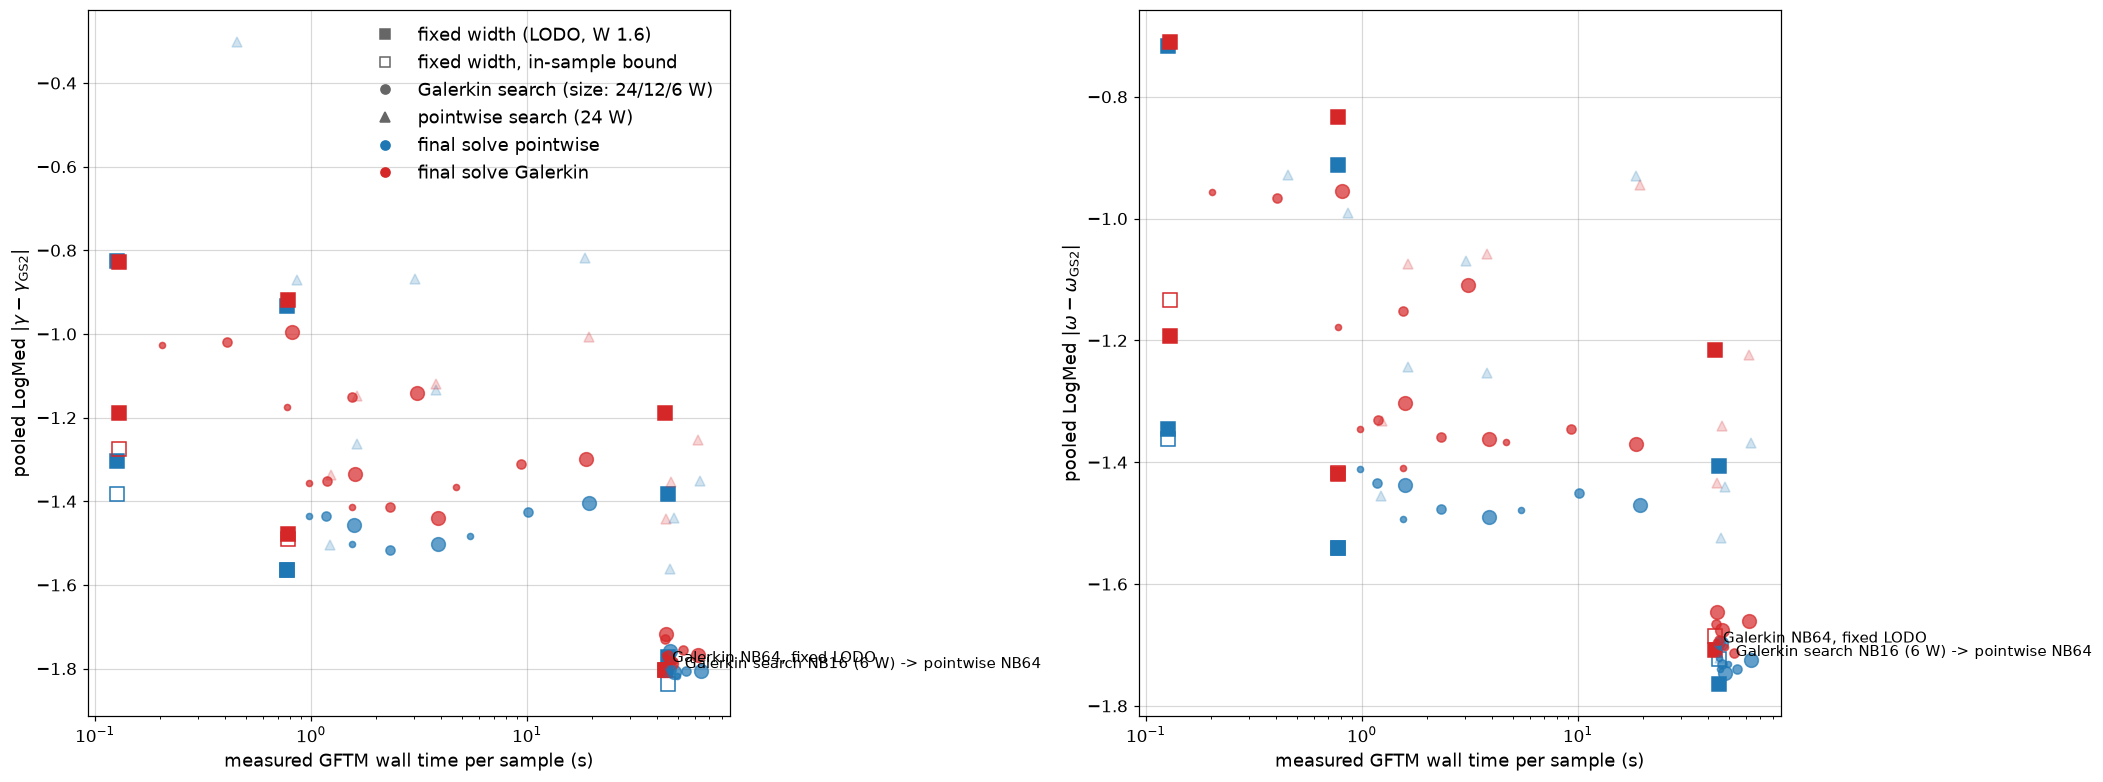

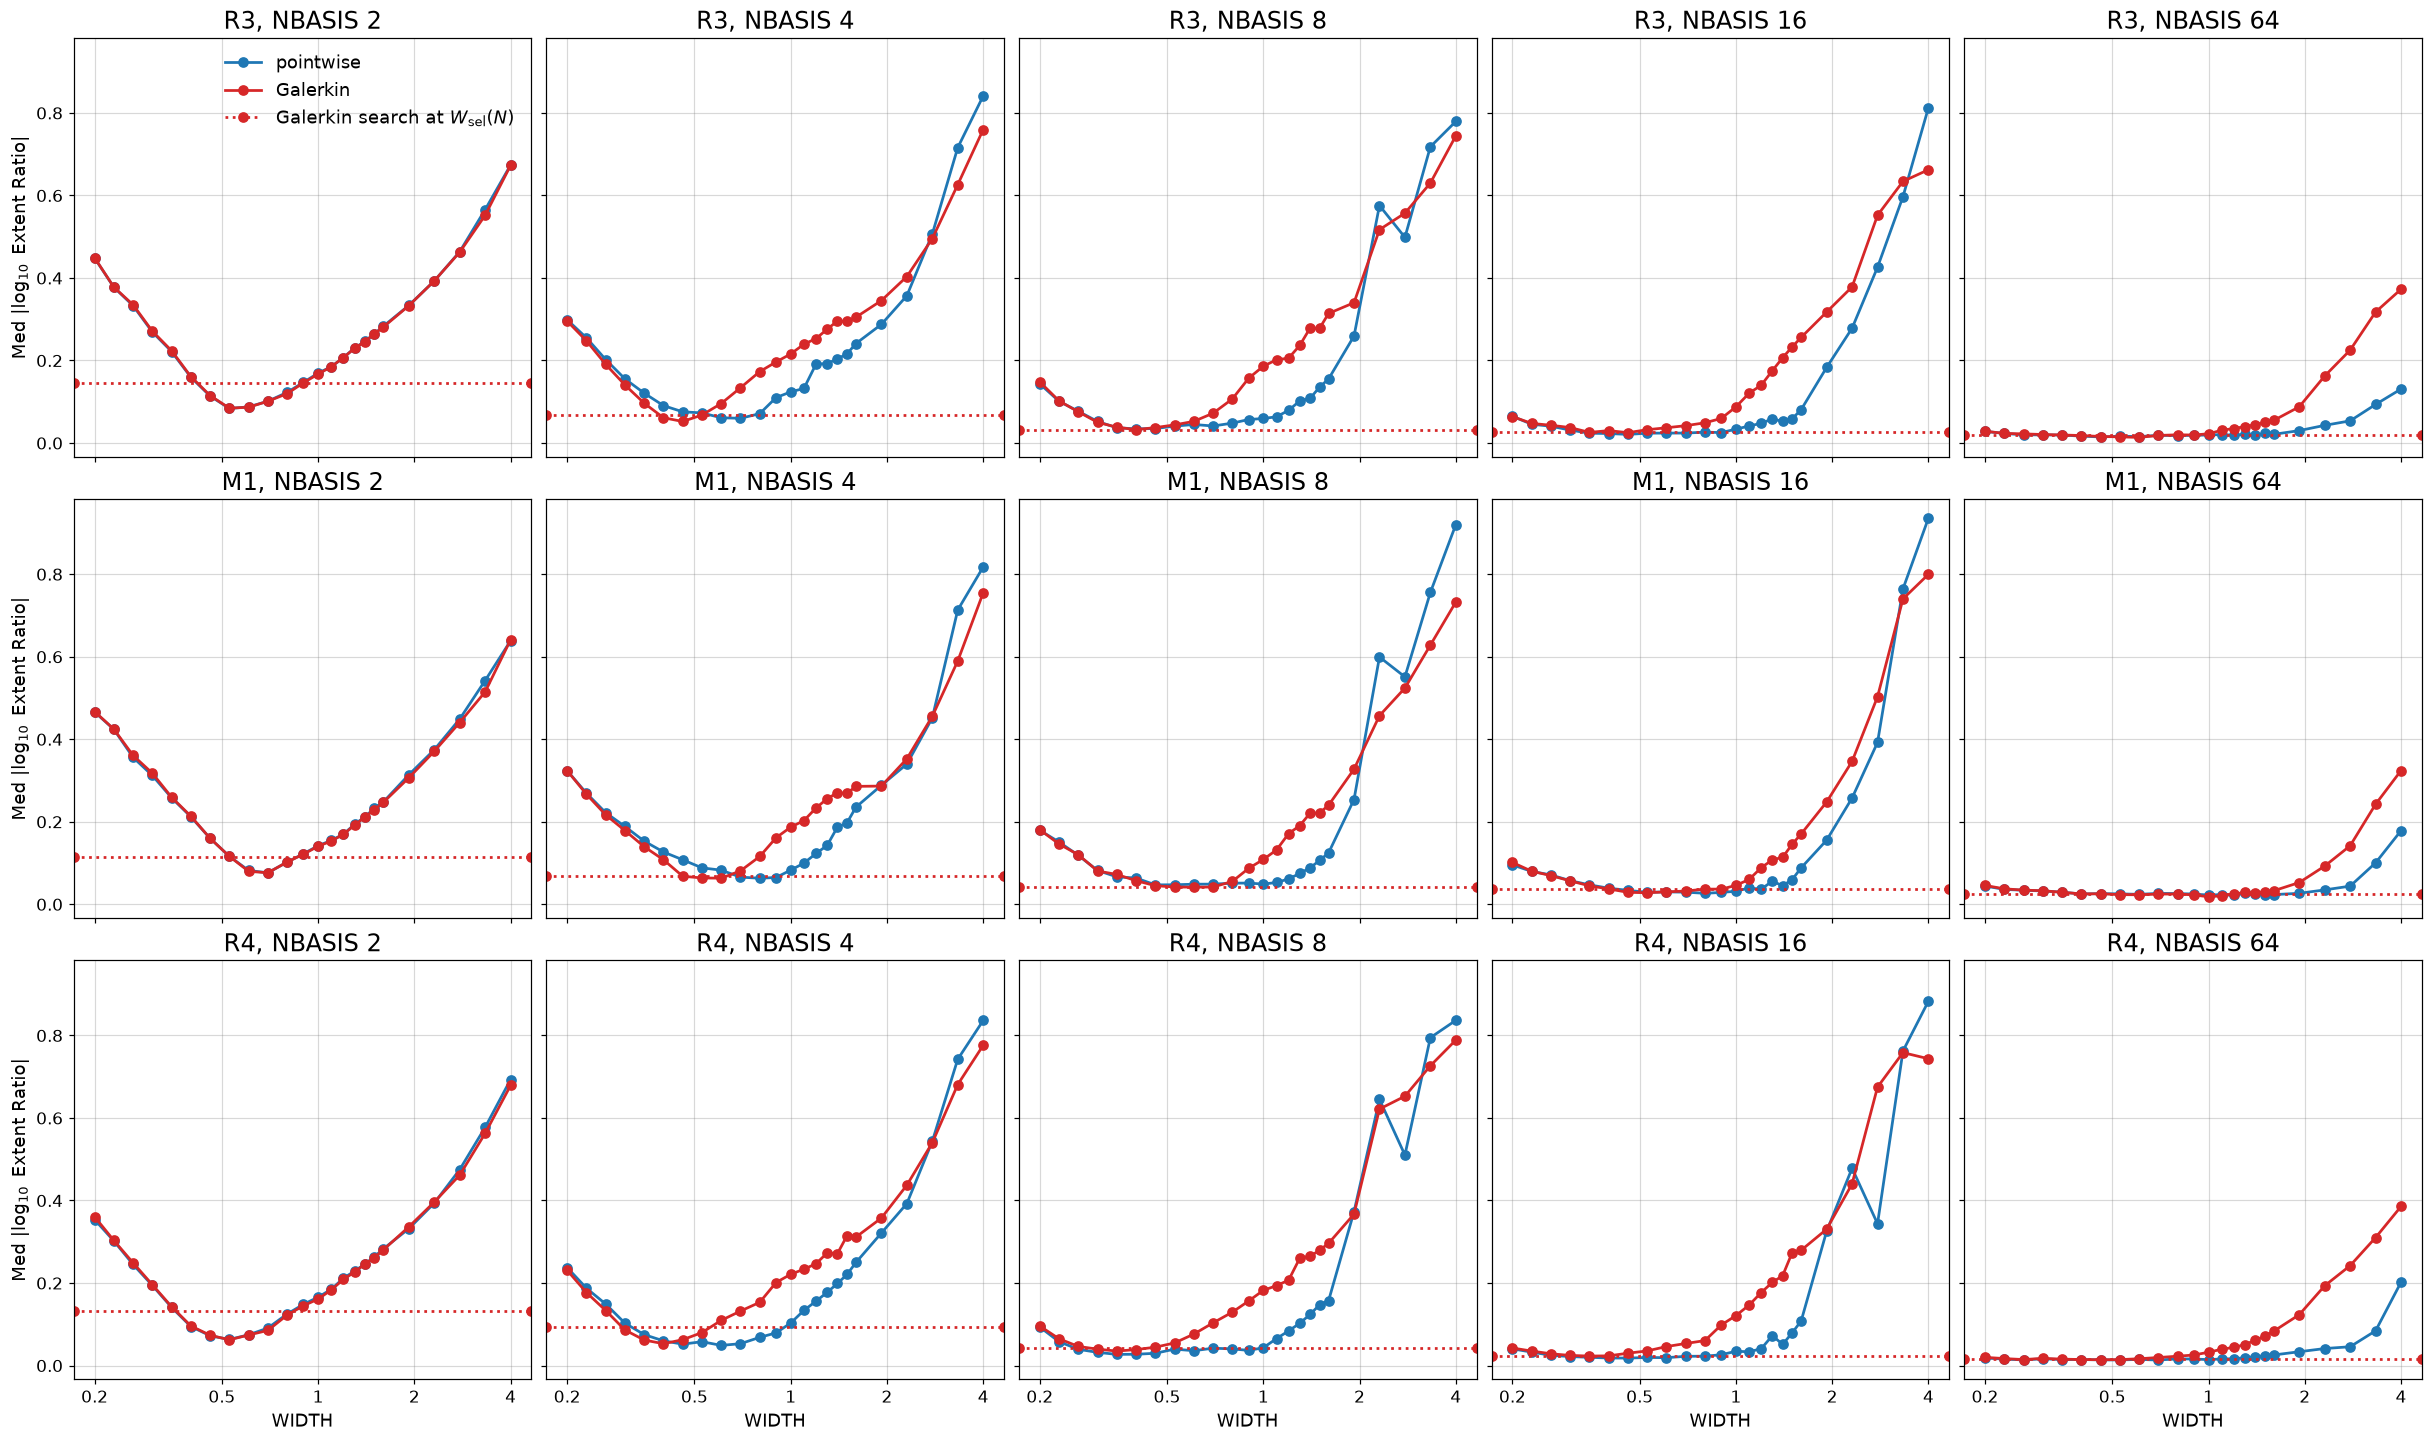

In [13]:
def scatter(quantity, scale):
    pairs = [(best_fixed, "fixed width"), (best_search, "Galerkin search")]
    values = {(label, case): (recipes[label]["values"][case][quantity], gs2[case][quantity]) for label, _ in pairs for case in cases}
    every = np.concatenate([np.concatenate(v) for v in values.values()])
    every = every[np.isfinite(every) & ((every > 0) if scale == "log" else True)]
    limits = (every.min() / 1.2, every.max() * 1.2) if scale == "log" else (every.min() - 0.05 * np.ptp(every), every.max() + 0.05 * np.ptp(every))
    symbol = r"\gamma" if quantity == "gamma" else r"\omega"
    fig, axes = plt.subplots(len(cases), 2, figsize=(12, 17), sharex=True, sharey=True, squeeze=False)
    for r, case in enumerate(cases):
        for j, (label, short) in enumerate(pairs):
            ax = axes[r, j]
            model, reference = values[label, case]
            error = np.abs(np.nan_to_num(model) - reference)
            ax.plot(reference, model, ls="", marker="o", alpha=0.5, color=arm_colours[recipes[label]["final_arm"]])
            ax.plot(limits, limits, color="k", ls="--", marker="")
            ax.set(xscale=scale, yscale=scale, xlim=limits, ylim=limits)
            ax.set_title(f"{case}, {short}: LogMed {np.log10(np.median(error)):.2f}", fontsize=fs_title)
            if r == len(cases) - 1:
                ax.set_xlabel(rf"${symbol}_{{\rm GS2}}$ ($c_s/a$)")
        axes[r, 0].set_ylabel(rf"${symbol}_{{\rm GFTM}}$ ($c_s/a$)")
    fig.suptitle(f"left: {best_fixed}\nright: {best_search}", fontsize=fs_legend)
    plt.show()
    return fig


fig6 = scatter("gamma", "log")
fig7 = scatter("omega", "linear")

fig8, axes8 = plt.subplots(2, len(cases), figsize=(19, 12), squeeze=False)
for r, (quantity, symbol) in enumerate((("gamma", r"\gamma"), ("omega", r"\omega"))):
    pooled_errors = [errors(recipes[label]["values"], cases)[r] for label in (best_fixed, best_search)]
    floor = min(error[error > 0].min() for error in pooled_errors) / 2
    limits = (floor, max(error.max() for error in pooled_errors) * 2)
    for ax, case in zip(axes8[r], cases):
        fixed_error, search_error = (np.maximum(errors(recipes[label]["values"], [case])[r], floor) for label in (best_fixed, best_search))
        ax.plot(fixed_error, search_error, ls="", marker="o", alpha=0.5)
        ax.plot(limits, limits, color="k", ls="--", marker="")
        ax.set(xscale="log", yscale="log", xlim=limits, ylim=limits,
               xlabel=rf"$|{symbol}-{symbol}_{{\rm GS2}}|$ fixed width", ylabel=rf"$|{symbol}-{symbol}_{{\rm GS2}}|$ Galerkin search")
        ax.set_title(f"{case}: {np.mean(search_error < fixed_error):.0%} below y=x", fontsize=fs_title)
fig8.suptitle(f"x: {best_fixed}   y: {best_search}", fontsize=fs_legend)
plt.show()

fig9, axes9 = plt.subplots(1, 2, figsize=(19, 7), sharex=True, squeeze=False)
for ax, (column, symbol) in zip(axes9[0], (("logmed_gamma", r"\gamma"), ("logmed_omega", r"\omega"))):
    for label, row in pooled.iterrows():
        recipe = recipes[label]
        colour = arm_colours[recipe["final_arm"]]
        if recipe["family"].startswith("fixed"):
            ax.plot(row.cost_s, row[column], marker="s", ls="", ms=9, color=colour,
                    mfc="none" if recipe["family"] == "fixed in-sample bound" else colour)
        elif recipe["family"] == "Galerkin search":
            ax.plot(row.cost_s, row[column], marker="o", ls="", ms={24: 9, 12: 6, 6: 4}[recipe["n_widths"]], color=colour, alpha=0.7)
        elif recipe["n_widths"] == 24:
            ax.plot(row.cost_s, row[column], marker="^", ls="", ms=6, color=colour, alpha=0.2)
    for label in (best_fixed, best_search):
        ax.annotate(label, (pooled.cost_s[label], pooled[column][label]), fontsize=10, xytext=(5, 5), textcoords="offset points")
    ax.set(xscale="log", xlabel="measured GFTM wall time per sample (s)", ylabel=rf"pooled LogMed $|{symbol}-{symbol}_{{\rm GS2}}|$")
handles = [plt.Line2D([], [], marker=m, ls="", color="0.4", mfc=f, label=l) for m, f, l in
           (("s", "0.4", "fixed width (LODO, W 1.6)"), ("s", "none", "fixed width, in-sample bound"), ("o", "0.4", "Galerkin search (size: 24/12/6 W)"),
            ("^", "0.4", "pointwise search (24 W)"))] + \
          [plt.Line2D([], [], marker="o", ls="", color=arm_colours[arm], label=f"final solve {arms[arm]}") for arm in arms]
axes9[0, 0].legend(handles=handles, fontsize=fs_legend)
plt.show()

rows = []
for (case, arm, nbasis, width), entry in gftm.items():
    rows.append(dict(case=case, arm=arm, nb=nbasis, W=width, extent_dex=np.nanmedian(np.abs(np.log10(entry["extent"] / gs2[case]["extent"])))))
extent_vs_width = pd.DataFrame(rows).sort_values(["case", "arm", "nb", "W"])
fig10, axes10 = plt.subplots(len(cases), len(nbasis_all), figsize=(22, 13), sharex=True, sharey=True, squeeze=False)
for r, case in enumerate(cases):
    for j, nb in enumerate(nbasis_all):
        ax = axes10[r, j]
        for arm in arms:
            a = extent_vs_width[(extent_vs_width.case == case) & (extent_vs_width.arm == arm) & (extent_vs_width.nb == nb)]
            ax.plot(a.W, a.extent_dex, color=arm_colours[arm], label=arms[arm])
        search = accuracy[(accuracy.case == case) & (accuracy.arm == "T") & (accuracy.nbasis == nb)].extent_ratio.item()
        ax.axhline(search, color=arm_colours["T"], ls=":", label=r"Galerkin search at $W_{\rm sel}(N)$")
        ax.set(xscale="log")
        ax.set_title(f"{case}, NBASIS {nb}", fontsize=fs_title)
        if r == len(cases) - 1:
            ax.set_xlabel("WIDTH")
            log_xticks(ax, [0.2, 0.5, 1, 2, 4])
    axes10[r, 0].set_ylabel(r"Med $|\log_{10}$ Extent Ratio$|$")
axes10[0, 0].legend(fontsize=fs_legend)
plt.show()

In [14]:
out = ROOT / "Plots" / analysis_name
out.mkdir(parents=True, exist_ok=True)
for name, fig in (("fig0_w_shape_phase_check", fig_phase), ("fig1_overshoot_vs_nbasis", fig1), ("fig2_width_selection_vs_nbasis", fig2),
                  ("fig3_gamma_err_at_selected_width", fig3), ("fig3b_extent_ratio_at_selected_width", fig3b),
                  ("fig4_mode_identity_vs_ky", fig4), ("fig5_gamma_err_vs_width_per_nbasis", fig5),
                  ("fig6_gamma_scatter_fixed_vs_search", fig6), ("fig7_omega_scatter_fixed_vs_search", fig7),
                  ("fig8_paired_error_fixed_vs_search", fig8), ("fig9_accuracy_vs_cost", fig9),
                  ("fig10_extent_err_vs_width_per_nbasis", fig10)):
    fig.savefig(out / f"{name}.png", bbox_inches="tight")
# medians and shares only, no per-sample rows
for name, table in (("overshoot", overshoot), ("width_selection", width_selection), ("accuracy_at_selected_width", accuracy),
                    ("mode_identity", identity), ("accuracy_vs_width", acc),
                    ("recipe_scores", scores), ("paired_search_vs_fixed", paired_scores), ("solve_seconds", timing_summary),
                    ("w_gamma_spread", w_gamma_spread), ("extent_vs_width", extent_vs_width)):
    table.round(4).to_csv(out / f"{name}.csv", index=False)
print(sorted(p.name for p in out.iterdir()))

['accuracy_at_selected_width.csv', 'accuracy_vs_width.csv', 'extent_vs_width.csv', 'fig0_w_shape_phase_check.png', 'fig10_extent_err_vs_width_per_nbasis.png', 'fig1_overshoot_vs_nbasis.png', 'fig2_width_selection_vs_nbasis.png', 'fig3_gamma_err_at_selected_width.png', 'fig3b_extent_ratio_at_selected_width.png', 'fig4_mode_identity_vs_ky.png', 'fig5_gamma_err_vs_width_per_nbasis.png', 'fig6_gamma_scatter_fixed_vs_search.png', 'fig7_omega_scatter_fixed_vs_search.png', 'fig8_paired_error_fixed_vs_search.png', 'fig9_accuracy_vs_cost.png', 'mode_identity.csv', 'overshoot.csv', 'paired_search_vs_fixed.csv', 'recipe_scores.csv', 'solve_seconds.csv', 'w_gamma_spread.csv', 'width_selection.csv']
